# Value at Risk and Stress Testing for a Mexican Multi-Asset Portfolio

**Business question:** How much could a MXN 100M portfolio of Mexican government bonds (40%), Mexican stocks (30%) and US dollars (30%) lose, and can the risk models used to measure it be trusted?

**Notebook structure**
- **Upload Data:** collect, store (SQLite) and validate 20 years of daily market data.
- **Section 1 - Risk factor analysis:** how stocks, the peso and bond yields behave, and the portfolio's daily P&L.
- **Section 2 - VaR and Expected Shortfall:** how much the portfolio could lose on a normal bad day.
- **Section 3 - Backtesting:** whether the VaR models would have worked over 2008–2026.
- **Section 4 - Stress testing:** how much it could lose in a crisis.
- **Section 5 - Conclusions:** alternative portfolio mixes, overall summary and recommendations.

**Data:** daily USD/MXN and CETES 28 (Banxico SIE API), IPC index (Yahoo Finance), 10-year M Bono yield (Investing.com), Jan 2007 – Nov 2026.

# Initial Setup

Import packages

1. pandas & numpy: data manipulation and array calculations
2. requests: pulling data from the Banxico SIE API
3. yfinance: downloading the IPC index from Yahoo Finance
4. sqlite3: storing the raw data in a SQLite database and querying it with SQL
5. scipy: statistical tests and distributions
6. matplotlib: data visualisation

In [105]:
import pandas as pd
import numpy as np
import requests
import yfinance as yf
import sqlite3
from google.colab import userdata      # reads secrets (API token) stored in Colab
from scipy import stats
import matplotlib.pyplot as plt
from scipy.special import xlogy          # x * log(y) that returns 0 when x = 0 (needed for the tests)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.optimize import brentq        # solver used in the reverse stress test
import os
os.makedirs("/content/images", exist_ok=True)   # folder for chart images used in the README

Settings to show all rows & columns permanently for the rest of this notebook

In [100]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

# Upload Data

Date range and GitHub repository

In [ ]:
# Data period: Jan 2007 (so the 2008 crisis is included) up to today
START = "2007-01-01"
END = pd.Timestamp.today().strftime("%Y-%m-%d")

# Clone the project repo (contains the bond yield CSV files downloaded from Investing.com)
!rm -rf VaR-Stress-Testing
!git clone https://github.com/celynhs/VaR-Stress-Testing.git

Cloning into 'VaR-Stress-Testing'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 11 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), 62.11 KiB | 2.22 MiB/s, done.


USD/MXN exchange rate and CETES 28-day rate (Banxico SIE API)

In [ ]:
# Banxico API token is stored as a Colab secret (key icon in the left sidebar), so it never appears in the notebook
token = userdata.get('BANXICO_TOKEN')

# SF43718 = USD/MXN FIX rate (pesos per 1 US dollar), SF43936 = CETES 28-day rate (weekly auction, %)
series_ids = {"SF43718": "usdmxn", "SF43936": "cetes28"}
url = (f"https://www.banxico.org.mx/SieAPIRest/service/v1/series/"
       f"{','.join(series_ids)}/datos/{START}/{END}")

response = requests.get(url, headers={"Bmx-Token": token})
response.raise_for_status()                      # stop with an error if the request failed

banxico_frames = []
for s in response.json()["bmx"]["series"]:
    df = pd.DataFrame(s["datos"])
    df["date"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y")                     # Banxico dates are dd/mm/yyyy
    df["value"] = pd.to_numeric(df["dato"].str.replace(",", ""), errors="coerce")  # "N/E" (not available) -> NaN
    df["series_id"] = series_ids[s["idSerie"]]
    df["source"] = "Banxico SIE"
    banxico_frames.append(df[["date", "series_id", "value", "source"]])

banxico = pd.concat(banxico_frames).dropna(subset=["value"])
banxico.groupby("series_id")["date"].agg(["min", "max", "count"])

,min,max,count
series_id,,,
cetes28,2007-01-04,2026-11-12,1037
usdmxn,2007-01-02,2026-11-17,4998


IPC index (Mexican stock market) from Yahoo Finance

In [ ]:
ipc_raw = yf.download("^MXX", start=START, end=END, auto_adjust=True, progress=False)

ipc = (ipc_raw["Close"].squeeze()          # newer yfinance returns multi-level columns -> squeeze to one column
       .rename("value").reset_index()
       .rename(columns={"Date": "date"}))
ipc["series_id"] = "ipc"
ipc["source"] = "Yahoo Finance"
ipc = ipc[["date", "series_id", "value", "source"]].dropna()

print(ipc["date"].min().date(), "to", ipc["date"].max().date(), "|", len(ipc), "rows")

2007-01-02 to 2026-11-17 | 4984 rows


10-year M Bono yield (Mexican government bond) from Investing.com

In [ ]:
# Investing.com allows max 5,000 rows per download, so the history is split across two files
bond_files = ['/content/VaR-Stress-Testing/data/mbono10y.csv',
              '/content/VaR-Stress-Testing/data/mbono10y_2.csv']

bond_raw = pd.concat([pd.read_csv(f) for f in bond_files], ignore_index=True)

bond = pd.DataFrame({
    "date": pd.to_datetime(bond_raw["Date"], format="%m/%d/%Y"),
    "series_id": "mbono10y",
    "value": pd.to_numeric(bond_raw["Price"], errors="coerce"),   # "Price" = yield in % per year
    "source": "Investing.com"
}).dropna().drop_duplicates(subset="date").sort_values("date").reset_index(drop=True)

print(bond["date"].min().date(), "to", bond["date"].max().date(), "|", len(bond), "rows")

2007-01-02 to 2026-11-17 | 5458 rows


Check: weekend rows in the bond data

In [ ]:
# Markets don't trade on weekends. Check whether the weekend rows are copies of Friday (harmless)
# or separate quotes (a sign the dates in those months may be shifted by one day)
bond["dow"] = bond["date"].dt.dayofweek                 # 0 = Monday ... 5 = Saturday, 6 = Sunday
weekend = bond[bond["dow"] >= 5].copy()

prev_friday = weekend["date"] - pd.to_timedelta(weekend["dow"] - 4, unit="D")
friday_values = bond.set_index("date")["value"]
weekend["friday_value"] = prev_friday.map(friday_values)

print("Weekend rows:", len(weekend))
print("% where the Friday row also exists:", round(weekend["friday_value"].notna().mean() * 100, 1))
print("% where weekend value = Friday value:", round((weekend["value"] == weekend["friday_value"]).mean() * 100, 1))

affected_months = weekend["date"].dt.to_period("M").unique()
print("Months with weekend rows:", len(affected_months), "| from", affected_months.min(), "to", affected_months.max())

Weekend rows: 478
% where the Friday row also exists: 99.8
% where weekend value = Friday value: 1.5
Months with weekend rows: 111 | from 2012-07 to 2024-08


**Outcome:** The bond file has 478 weekend rows. The Friday row exists for 99.8% of them, but only 1.5% have the same value as Friday, so they are **separate quotes, not copies**. They appear in 111 months between Jul 2012 and Aug 2024. The next step tests which version of the dates is correctly aligned.

Check: date alignment in the affected months

In [ ]:
# Option A: drop the weekend rows and keep the other dates as downloaded
# Option B: shift every row in the affected months back one day (Sat -> Fri, Tue -> Mon, ...)
# Bond yields and USD/MXN normally move together on the SAME day, so the option with the
# higher same-day correlation (measured only in the affected months) has the correct dates.
fx = banxico.loc[banxico["series_id"] == "usdmxn"].set_index("date")["value"]

def alignment_corr(bond_series, months):
    """Same-day correlation between bond yield changes and USD/MXN % changes, within the given months."""
    df = pd.concat({"bond": bond_series, "fx": fx}, axis=1, join="inner").sort_index()
    chg = pd.DataFrame({"bond": df["bond"].diff(), "fx": df["fx"].pct_change()}).dropna()
    chg = chg[chg.index.to_period("M").isin(months)]
    return round(chg["bond"].corr(chg["fx"]), 3), len(chg)

in_affected = bond["date"].dt.to_period("M").isin(affected_months)

option_a = bond.loc[bond["dow"] < 5].set_index("date")["value"]

shifted = bond.copy()
shifted.loc[in_affected, "date"] -= pd.Timedelta(days=1)
shifted = shifted[shifted["date"].dt.dayofweek < 5].drop_duplicates(subset="date", keep="last")
option_b = shifted.set_index("date")["value"]

alignment = pd.DataFrame(
    [alignment_corr(option_a, affected_months), alignment_corr(option_b, affected_months)],
    columns=["bond_vs_fx_corr", "days_compared"],
    index=["A: drop weekend rows (dates as downloaded)", "B: shift affected months back 1 day"])
display(alignment)

# Keep the better-aligned version
use_shift = alignment["bond_vs_fx_corr"].iloc[1] > alignment["bond_vs_fx_corr"].iloc[0]
chosen = option_b if use_shift else option_a
print("Chosen:", "B (shift back 1 day)" if use_shift else "A (drop weekend rows)")

bond = pd.DataFrame({"date": chosen.index, "series_id": "mbono10y",
                     "value": chosen.values, "source": "Investing.com"}).sort_values("date").reset_index(drop=True)
print(bond["date"].min().date(), "to", bond["date"].max().date(), "|", len(bond), "rows")

,bond_vs_fx_corr,days_compared
A: drop weekend rows (dates as downloaded),0.387,2325
B: shift affected months back 1 day,0.040,2273


Chosen: A (drop weekend rows)
2007-01-02 to 2026-11-17 | 4980 rows


**Outcome:** In the affected months, keeping the dates as downloaded and dropping the weekend rows (option A) gives a bond-vs-FX correlation of 0.387 over 2,325 days, while shifting the months back one day (option B) drops it to 0.040. The downloaded dates are therefore correctly aligned, and the weekend rows are extra quotes that can be removed. Option A is used, leaving 4,980 weekday bond rows from 2 Jan 2007 to 17 Nov 2026.

Write to SQLite

In [ ]:
# Stack all sources into one long table: one row per (date, series)
raw_series = pd.concat([banxico, ipc, bond], ignore_index=True)
raw_series["date"] = raw_series["date"].dt.strftime("%Y-%m-%d")    # SQLite stores dates as text

conn = sqlite3.connect("/content/market.db")
raw_series.to_sql("raw_series", conn, if_exists="replace", index=False)
conn.execute("CREATE INDEX IF NOT EXISTS idx_date_series ON raw_series(date, series_id)")

# Coverage check per series
pd.read_sql("""
    SELECT series_id, source, MIN(date) AS first_date, MAX(date) AS last_date, COUNT(*) AS n_obs
    FROM raw_series
    GROUP BY series_id, source
""", conn)

,series_id,source,first_date,last_date,n_obs
0,cetes28,Banxico SIE,2007-01-04,2026-11-12,1037
1,ipc,Yahoo Finance,2007-01-02,2026-11-17,4984
2,mbono10y,Investing.com,2007-01-02,2026-11-17,4980
3,usdmxn,Banxico SIE,2007-01-02,2026-11-17,4998


Pivot to one row per date (SQL)

In [ ]:
# Turn the long table wide (one column per series) and keep only dates where
# all three portfolio series exist (drops holidays and missing days)
query = """
WITH pivoted AS (
    SELECT date,
           MAX(CASE WHEN series_id = 'usdmxn'   THEN value END) AS usdmxn,
           MAX(CASE WHEN series_id = 'ipc'      THEN value END) AS ipc,
           MAX(CASE WHEN series_id = 'mbono10y' THEN value END) AS mbono10y,
           MAX(CASE WHEN series_id = 'cetes28'  THEN value END) AS cetes28
    FROM raw_series
    GROUP BY date
)
SELECT *
FROM pivoted
WHERE usdmxn IS NOT NULL AND ipc IS NOT NULL AND mbono10y IS NOT NULL
ORDER BY date
"""
market = pd.read_sql(query, conn, parse_dates=["date"]).set_index("date")

# CETES 28 is a weekly auction rate, so carry the last value forward between auctions
market["cetes28"] = market["cetes28"].ffill()
market.head()

,usdmxn,ipc,mbono10y,cetes28
date,,,,
2007-01-02,10.7815,26664.449219,7.42,NaN
2007-01-03,10.7708,26619.369141,7.41,NaN
2007-01-04,10.8650,26566.279297,7.45,7.01
2007-01-05,10.9355,26135.599609,7.50,7.01
2007-01-08,10.9705,26281.640625,7.54,7.01


Check: holidays

In [ ]:
# Dates with a bond yield but no FX rate. Banxico doesn't publish the FIX on Mexican bank holidays
fx_dates = set(fx.index)
bond_dates = set(bond["date"])

extra = pd.Series(sorted(bond_dates - fx_dates), dtype="datetime64[ns]")
print("Bond dates with no FX value:", len(extra))
print(extra.dt.day_name().value_counts())
print(extra.tail(10))

Bond dates with no FX value: 65
Monday       22
Thursday     18
Friday       10
Wednesday     9
Tuesday       6
Name: count, dtype: int64
55   2025-12-12
56   2026-01-01
57   2026-02-02
58   2026-03-16
59   2026-04-02
60   2026-04-03
61   2026-05-01
62   2026-09-16
63   2026-11-02
64   2026-11-16
dtype: datetime64[ns]


**Outcome:** 65 weekdays have a bond yield but no FX rate (22 Mondays, 18 Thursdays, 10 Fridays, 9 Wednesdays, 6 Tuesdays). They are Mexican bank holidays, e.g., 1 Jan, 2 Feb, 16 Mar, Holy Thursday and Good Friday, 1 May, 16 Sep, 2 Nov, 16 Nov and 12 Dec. Many Mexican holidays are moved to a Monday, which explains the large number of Mondays. Banxico does not publish the FIX on these days, so they are excluded from the final table.

Check: timing (lead-lag correlation)

In [ ]:
# The USD/MXN FIX is set around midday in Mexico City; the IPC and bond yield are end-of-day closes.
# If that timing gap mattered, today's IPC/bond move would correlate more with TOMORROW's FIX.
chg = pd.DataFrame({
    "usdmxn": market["usdmxn"].pct_change(),
    "ipc":    market["ipc"].pct_change(),
    "bond":   market["mbono10y"].diff(),
}).dropna()

lag_check = pd.DataFrame({
    f"FX shifted {lag:+d} day": [chg["bond"].corr(chg["usdmxn"].shift(lag)),
                                 chg["ipc"].corr(chg["usdmxn"].shift(lag))]
    for lag in [-1, 0, 1]
}, index=["Bond vs USD/MXN", "IPC vs USD/MXN"]).round(3)
lag_check

,FX shifted -1 day,FX shifted +0 day,FX shifted +1 day
Bond vs USD/MXN,0.051,0.363,0.074
IPC vs USD/MXN,-0.158,-0.398,-0.031


**Outcome:** For the bond, the same-day correlation with USD/MXN (0.363) is far stronger than at ±1 day (0.051 and 0.074), so the dates are aligned. For the IPC, the same-day correlation is also the strongest (−0.398), but today's IPC move still has a correlation of −0.158 with **tomorrow's** FIX. This reflects the timing gap: the FIX is set at midday, so part of an afternoon stock move only shows up in the next day's exchange rate. As a result, the same-day IPC vs USD/MXN relationship, and the diversification between the IPC and USD legs, is slightly understated in daily data. This is noted as a limitation.

Check: bad bond prices

In [ ]:
# A bad price = a big one-day jump that reverses the next day while other markets are calm.
# Flag a bond yield when ALL of these are true:
#   - it moved 30 bp or more in one day (1 bp = 0.01 percentage point)
#   - the next day it moved back the opposite way by at least 40% of that move
#   - on the same day USD/MXN moved less than 1% and the IPC less than 2%
#     (this safeguard stops the rule from deleting real market shocks)
bond_chg_bp  = market["mbono10y"].diff() * 100
next_chg_bp  = bond_chg_bp.shift(-1)
fx_move_pct  = market["usdmxn"].pct_change().abs() * 100
ipc_move_pct = market["ipc"].pct_change().abs() * 100

bad_bond = ((bond_chg_bp.abs() >= 30)
            & (np.sign(next_chg_bp) == -np.sign(bond_chg_bp))
            & (next_chg_bp.abs() >= 0.4 * bond_chg_bp.abs())
            & (fx_move_pct < 1) & (ipc_move_pct < 2))

bad_bond_table = pd.DataFrame({
    "yield_before":   market["mbono10y"].shift(1),
    "yield":          market["mbono10y"],
    "yield_after":    market["mbono10y"].shift(-1),
    "change_bp":      bond_chg_bp,
    "next_change_bp": next_chg_bp,
    "usdmxn_move_%":  fx_move_pct,
    "ipc_move_%":     ipc_move_pct,
})[bad_bond].round(2)

print("Bond prices flagged by the rule:", bad_bond.sum())
bad_bond_table

Bond prices flagged by the rule: 1


,yield_before,yield,yield_after,change_bp,next_change_bp,usdmxn_move_%,ipc_move_%
date,,,,,,,
2016-11-14,7.22,7.54,7.05,32.0,-49.0,0.85,0.73


**Outcome:** The rule flagged 1 bond price: **14 Nov 2016** (7.22% → 7.54% → 7.05%), a +32 bp jump reversed by −49 bp the next day while USD/MXN moved only 0.85% and the IPC 0.73%. On review, this date falls inside the 2016 US election crisis window, when Mexican bond yields were highly volatile, so it is **kept as a real move**. In a risk analysis, genuine extreme moves are kept, because removing them would understate risk; only values with strong evidence of being errors are corrected.

Check: manual review of 6 Sep 2013

The rule's safeguard can also block a genuine bad price when the peso happens to move on the same day. 6 Sep 2013 is reviewed manually because it is one of the largest bond moves in the data (−60 bp) yet falls outside any crisis period.

In [ ]:
# Prices and daily moves around 6 Sep 2013 (before any correction)
review = market.loc["2013-09-02":"2013-09-11", ["usdmxn", "ipc", "mbono10y"]].copy()
review["usdmxn_move_%"]  = review["usdmxn"].pct_change() * 100
review["ipc_move_%"]     = review["ipc"].pct_change() * 100
review["bond_change_bp"] = review["mbono10y"].diff() * 100
review.round(2)

,usdmxn,ipc,mbono10y,usdmxn_move_%,ipc_move_%,bond_change_bp
date,,,,,,
2013-09-02,13.31,40129.04,6.30,NaN,NaN,NaN
2013-09-03,13.44,39541.51,6.40,0.99,-1.46,10.0
2013-09-04,13.31,39773.53,6.50,-0.99,0.59,10.0
2013-09-05,13.41,39686.45,6.57,0.76,-0.22,7.0
2013-09-06,13.24,39915.06,5.97,-1.24,0.58,-60.0
2013-09-09,13.15,40953.85,6.23,-0.71,2.60,26.0
2013-09-10,13.11,41732.98,6.35,-0.27,1.90,12.0
2013-09-11,13.09,41640.53,6.13,-0.14,-0.22,-22.0


**Outcome:** On 6 Sep 2013 the yield fell from 6.57% to 5.97% (−60 bp) and rose back to 6.23% the next day (+26 bp). The rule did not flag it only because USD/MXN moved 1.24% that day (the peso strengthened), just above the 1% safeguard. The evidence still points to a bad price:
- **Size:** −60 bp would rank among the 5 largest daily bond moves in 20 years; the other four occurred in the October 2008 and March 2020 crises.
- **Other markets were calm:** the IPC moved only +0.6%.
- **Reversal:** 26 bp of the drop reversed the next day, which a genuine repricing would not do.

It is therefore corrected manually alongside the rule-based flag.

Fix: replace bad bond prices

In [ ]:
# Rule-based flags + manually reviewed bad prints are replaced with the average of the neighbouring days.
# KEEP_AS_REAL = flagged dates that turn out to be real market events (left unchanged)
# MANUAL_BAD   = clear bad prints the rule missed (see manual review above)
KEEP_AS_REAL = ["2016-11-14"]   # inside the 2016 US election crisis window: plausibly a real move
MANUAL_BAD = ["2013-09-06"]

fix_dates = (bad_bond_table.index
             .difference(pd.to_datetime(KEEP_AS_REAL))
             .union(pd.to_datetime(MANUAL_BAD)))

before = market.loc[fix_dates, "mbono10y"].copy()
market.loc[fix_dates, "mbono10y"] = np.nan
market["mbono10y"] = market["mbono10y"].interpolate()     # linear interpolation = average of neighbours

print("Bond prices replaced:", len(fix_dates))
pd.DataFrame({"original_yield": before, "corrected_yield": market.loc[fix_dates, "mbono10y"]}).round(2)

Bond prices replaced: 1


,original_yield,corrected_yield
2013-09-06,5.97,6.4


**Outcome:** 1 bond price was replaced: 6 Sep 2013 (5.97% → 6.40%, the average of the neighbouring days). 14 Nov 2016 was kept as a real market move.

Check: multi-day changes

In [ ]:
# If one series is missing a business day, that date drops out of the table and the next change
# covers 2+ days of market movement, which overstates a "daily" move.
# Mexican business days = every day Banxico published the FIX.
fx_calendar = pd.DatetimeIndex(sorted(fx_dates))
position = pd.Series(fx_calendar.get_indexer(market.index), index=market.index)

market["business_days_spanned"] = position.diff()                    # 1 = a normal one-day change
market["multi_day_change"] = market["business_days_spanned"] > 1     # flag to exclude from daily analysis

# Which series caused the missing days?
skipped_days = fx_calendar.difference(market.index)
skipped = pd.DataFrame({
    "ipc_missing":  ~skipped_days.isin(pd.DatetimeIndex(ipc["date"])),
    "bond_missing": ~skipped_days.isin(pd.DatetimeIndex(bond["date"])),
}, index=skipped_days)

print("Mexican business days missing from the final table:", len(skipped_days))
display(skipped.sum().rename("days missing").to_frame())

print("Changes that span more than 1 business day:", int(market["multi_day_change"].sum()))
display(market["business_days_spanned"].value_counts().sort_index().rename("number of changes").to_frame())

Mexican business days missing from the final table: 97


,days missing
ipc_missing,14
bond_missing,83


Changes that span more than 1 business day: 50


,number of changes
business_days_spanned,
1.0,4850
2.0,35
3.0,11
4.0,2
6.0,1
30.0,1


**Outcome:** 97 Mexican business days are missing from the final table: 14 because of missing IPC values and 83 because of missing bond values. As a result, 50 changes span more than one business day: 35 span 2 days, 11 span 3 days, 2 span 4 days, 1 spans 6 days and 1 spans 30 days. These 50 changes are flagged in `multi_day_change` and excluded from the daily analysis in Section 1, so every change used later is a true one-day move.

Check: where are the longest gaps?

In [ ]:
# List every change that spans 3+ business days and which series was missing during the gap
ipc_days  = pd.DatetimeIndex(ipc["date"])
bond_days = pd.DatetimeIndex(bond["date"])

rows = []
for end, n in market.loc[market["business_days_spanned"] >= 3, "business_days_spanned"].items():
    prev = market.index[market.index.get_loc(end) - 1]                          # last date before the gap
    skipped_in_gap = fx_calendar[(fx_calendar > prev) & (fx_calendar < end)]    # business days inside the gap
    rows.append({"from": prev.date(), "to": end.date(), "business_days_spanned": int(n),
                 "ipc_missing":  int((~skipped_in_gap.isin(ipc_days)).sum()),
                 "bond_missing": int((~skipped_in_gap.isin(bond_days)).sum())})

long_gaps = pd.DataFrame(rows).sort_values("business_days_spanned", ascending=False).reset_index(drop=True)
long_gaps

,from,to,business_days_spanned,ipc_missing,bond_missing
0,2008-01-18,2008-03-03,30,0,29
1,2025-07-15,2025-07-23,6,0,5
2,2025-07-23,2025-07-29,4,0,3
3,2025-08-22,2025-08-28,4,0,3
4,2007-02-20,2007-02-23,3,0,2
5,2007-03-07,2007-03-12,3,0,2
6,2007-02-14,2007-02-19,3,0,2
7,2007-10-17,2007-10-22,3,0,2
8,2007-10-23,2007-10-26,3,0,2
9,2025-08-05,2025-08-08,3,0,2


**Outcome:** 15 changes span 3 or more business days, and **all of them are caused by missing bond data** (the IPC is missing on 0 of those days). The longest is a 30-business-day gap from 18 Jan 2008 to 3 Mar 2008 (29 bond days missing), so about six weeks of market movement are not observed. This explains the +10.53% IPC "daily" move on 3 Mar 2008 seen earlier: it was six weeks of movement recorded as one day. The gap falls before the 2008 GFC crisis window (Sep 2008 – Mar 2009), so the stress tests are not affected.

The remaining gaps cluster in two periods:
- **Feb–Oct 2007:** 5 gaps of 3 business days.
- **Jul–Sep 2025:** 9 gaps of 3 to 6 business days (the longest from 15 to 23 Jul 2025), meaning the bond data is patchy over these three months.

The 2025 gaps matter more than the older ones, because the most recent data is what a rolling 250-day VaR uses for today's risk estimate. Those weeks are covered with fewer bond observations, which is noted as a limitation.

Final clean dataset

In [ ]:
print("Final table:", len(market), "trading days |",
      market.index.min().date(), "to", market.index.max().date())
print("Clean one-day changes available:", int((market["business_days_spanned"] == 1).sum()))

market.to_csv("/content/market_clean.csv")      # saved so later notebooks don't need the API again
market.head()

Final table: 4901 trading days | 2007-01-02 to 2026-11-17
Clean one-day changes available: 4850


,usdmxn,ipc,mbono10y,cetes28,business_days_spanned,multi_day_change
date,,,,,,
2007-01-02,10.7815,26664.449219,7.42,NaN,NaN,False
2007-01-03,10.7708,26619.369141,7.41,NaN,1.0,False
2007-01-04,10.8650,26566.279297,7.45,7.01,1.0,False
2007-01-05,10.9355,26135.599609,7.50,7.01,1.0,False
2007-01-08,10.9705,26281.640625,7.54,7.01,1.0,False


**Summary - Data Collection and Preparation**

**What was done**
- Collected daily market data from 2 Jan 2007 to 17 Nov 2026:
  - **USD/MXN FIX exchange rate** (4,998 days) and **CETES 28-day rate** (1,037 weekly auctions) from the Banxico SIE REST API, authenticated with a token stored as a Colab secret.
  - **S&P/BMV IPC index** (4,984 days) from Yahoo Finance via `yfinance`.
  - **10-year M Bono yield** (5,458 rows before cleaning) from Investing.com, downloaded as two CSV files because of the 5,000-row download limit.
- Stored all sources in one long table in SQLite and used SQL to pivot it to one row per trading date.
- Ran six data checks (weekend rows, date alignment, holidays, timing, bad prices, multi-day changes) and corrected the issues before any analysis.

**Data quality issues found and fixed**
- **Weekend rows:** 478 Saturday/Sunday rows (Jul 2012 – Aug 2024) were separate quotes, not copies of Friday. An alignment test showed the downloaded dates are correct (bond-vs-FX correlation 0.387, vs 0.040 if shifted), so the weekend rows were removed, leaving 4,980 bond rows.
- **Holidays:** 65 weekdays with a bond yield but no FX rate were Mexican bank holidays and were excluded.
- **Bad bond prices:** extreme moves were kept as genuine market risk unless there was strong evidence of a data error. 14 Nov 2016 was flagged by the rule but kept, as it falls inside the 2016 US election crisis window. 6 Sep 2013 (−60 bp on a calm day, partly reversed the next day) was judged a bad print and replaced with the average of the neighbouring days (6.40%).
- **Multi-day changes:** 97 business days were missing from at least one series (83 bond, 14 IPC), so 50 changes spanned more than one day. All gaps of 3+ days come from the bond data, including a 30-business-day gap (18 Jan – 3 Mar 2008) and patchy coverage in Jul–Sep 2025. These changes were flagged and excluded from the daily analysis rather than filled, so no data was invented.
- **Timing:** the bond and FX series are aligned (same-day correlation 0.363 vs 0.074 or less at ±1 day). The midday FIX causes a small lag between the IPC and FX (−0.158 with the next day's FIX).
- **Weekly CETES:** carried forward between auctions; used only as context for the interest-rate stress scenario.

**Outcome**
- A validated dataset of **4,901 trading days** with **4,850 clean one-day changes**, covering the 2008 GFC, the 2016 US election and 2020 COVID stress periods.
- Columns: `usdmxn` (pesos per US dollar; up = peso weaker), `ipc` (stock index level), `mbono10y` (10-year yield, % per year), `cetes28` (28-day T-bill rate, %), plus the quality flags `business_days_spanned` and `multi_day_change`.

**Limitations**
- The bond series is a generic 10-year benchmark from a single free source (Investing.com), and one bad price was corrected by analyst judgement rather than a fixed rule.
- The FIX is set at midday while the IPC and bond yield are end-of-day closes, so the same-day IPC vs USD/MXN correlation, and the diversification between those two legs, is slightly understated.
- Excluding 50 multi-day changes removes some days of market movement, including a six-week bond data gap in early 2008 (before the GFC window) and patchy bond data in Jul–Sep 2025, which slightly reduces the observations behind recent VaR estimates.

# Section 1 - Risk Factor Analysis and Portfolio P&L

**Objective:** Understand how the three market risk factors (stocks, the peso and bond yields) behave day to day and how they move together, then turn their daily moves into a daily profit/loss (P&L) in MXN for the portfolio. This P&L series is the input for the VaR, backtesting and stress testing in Sections 2–4.

**Key terms**
- **Risk factor:** a market price whose movement changes the portfolio's value (here: the IPC index, the USD/MXN exchange rate and the 10-year bond yield).
- **P&L (profit and loss):** how much money the portfolio made (+) or lost (−) on a given day.
- **Fat tails:** extreme days (crashes and spikes) happen more often than a normal "bell curve" predicts.

## 1.1 Portfolio setup

This step defines the hypothetical portfolio being risk-managed: **MXN 100 million**, split 40% Mexican government bonds, 30% Mexican stocks (IPC) and 30% US dollars. This kind of mix is typical of a Mexican bank treasury, pension fund (Afore) or insurer.

It also sets two things reused later: the **crisis windows** used to compare normal vs stressed markets, and the chart colours.

In [ ]:
# --- Portfolio definition ---
PORTFOLIO_VALUE = 100_000_000                      # MXN 100M total
WEIGHTS = {"bond": 0.40, "ipc": 0.30, "usd": 0.30} # share of the portfolio in each asset
POSITIONS = {k: w * PORTFOLIO_VALUE for k, w in WEIGHTS.items()}  # MXN amount in each asset

# --- Bond assumptions ---
BOND_MATURITY_YEARS = 10   # 10-year M Bono
COUPONS_PER_YEAR = 2       # M Bonos pay interest every 182 days (twice a year)

# --- Crisis windows (well-known stress periods, used to compare calm vs crisis markets) ---
CRISIS_WINDOWS = {
    "2008 GFC":         ("2008-09-01", "2009-03-31"),  # Lehman collapse, global financial crisis
    "2016 US election": ("2016-11-01", "2017-01-31"),  # peso sell-off on US trade/tariff fears
    "2020 COVID":       ("2020-02-15", "2020-04-30"),  # global pandemic market panic
}

# --- Chart colours (one fixed colour per portfolio leg, used in every chart) ---
COLORS = {"bond": "#2a78d6", "ipc": "#eb6834", "usd": "#1baf7a", "total": "#0b0b0b"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "font.size": 10})

pd.DataFrame({"weight": WEIGHTS,
              "position_MXN_m": {k: v / 1e6 for k, v in POSITIONS.items()}})

,weight,position_MXN_m
bond,0.4,40.0
ipc,0.3,30.0
usd,0.3,30.0


**Outcome:** The portfolio holds MXN 40M in 10-year M Bonos, MXN 30M in the IPC index and MXN 30M in US dollars. The weights are kept fixed every day (the portfolio is assumed to be rebalanced daily), so the risk measured later reflects **today's** mix applied to 20 years of market history.

## 1.2 Daily changes in the risk factors

VaR measures the risk of **changes**, not price levels, so each series is converted into a daily change:
- **IPC return (%):** how much the stock index moved.
- **USD/MXN return (%):** how much the dollar moved against the peso. Positive = peso **weakened**.
- **Bond yield change (bp):** how much the 10-year yield moved, in basis points (1 bp = 0.01 percentage point; 7.42% → 7.50% is +8 bp).

Only **true one-day changes** are kept (changes spanning more than one business day were flagged during data preparation). The 5 largest moves for each factor are listed as a final sanity check that extreme values match real market events.

In [ ]:
factors = pd.DataFrame(index=market.index)
factors["ipc_ret"]    = market["ipc"].pct_change()         # daily % change (as a decimal: 0.01 = 1%)
factors["usdmxn_ret"] = market["usdmxn"].pct_change()      # positive = peso weakened vs USD
factors["bond_dy_bp"] = market["mbono10y"].diff() * 100    # daily yield change in basis points
factors = factors[~market["multi_day_change"]].dropna()    # keep only true one-day changes

print("Daily observations:", len(factors), "|",
      factors.index.min().date(), "to", factors.index.max().date())

# Sanity check: the 5 biggest moves (up or down) for each factor, with dates
labels = {"ipc_ret": "IPC return (%)", "usdmxn_ret": "USD/MXN return (%)", "bond_dy_bp": "Bond yield change (bp)"}
for col, label in labels.items():
    top = factors.loc[factors[col].abs().nlargest(5).index, col]
    if col != "bond_dy_bp":
        top = top * 100                                     # show returns in %
    print(f"\n{label} - 5 largest moves")
    display(top.round(2).to_frame(label))

Daily observations: 4850 | 2007-01-03 to 2026-11-17

IPC return (%) - 5 largest moves


,IPC return (%)
date,
2008-10-13,11.01
2008-10-28,10.31
2008-10-22,-7.01
2008-11-24,7.00
2020-03-09,-6.42



USD/MXN return (%) - 5 largest moves


,USD/MXN return (%)
date,
2016-11-09,7.65
2008-10-08,7.61
2008-10-06,5.83
2008-10-13,-5.44
2008-10-10,5.17



Bond yield change (bp) - 5 largest moves


,Bond yield change (bp)
date,
2008-10-28,-90.0
2008-10-22,81.0
2020-03-20,-77.0
2008-10-27,-64.0
2023-10-04,-53.1


**Finding:**

**After cleaning, every one of the largest daily moves falls on a known stress event**
- The clean data has 4,850 daily observations from 3 Jan 2007 to 17 Nov 2026.
- IPC: the largest moves were +11.01% (13 Oct 2008), +10.31% (28 Oct 2008), −7.01% (22 Oct 2008) and +7.00% (24 Nov 2008) during the global financial crisis, and −6.42% on 9 Mar 2020, the oil price crash at the start of the COVID sell-off.
- USD/MXN: the largest move was +7.65% on 9 Nov 2016 (the day after the US election, when the peso weakened sharply), followed by October 2008 moves of +7.61% (8 Oct), +5.83% (6 Oct), −5.44% (13 Oct, a relief-rally rebound) and +5.17% (10 Oct).
- Bond yield: the largest moves were −90 bp (28 Oct 2008), +81 bp (22 Oct 2008) and −64 bp (27 Oct 2008) during the crisis, −77 bp on 20 Mar 2020 (COVID, when Banxico made an emergency rate cut) and −53.1 bp on 4 Oct 2023 (the global bond sell-off).
- The two IPC moves previously caused by missing days (3 Mar 2008 and 27 Feb 2007) and the corrected bond price (6 Sep 2013) no longer appear, confirming the data cleaning worked. All remaining extremes are genuine market moves and are kept.

## 1.3 Descriptive statistics and fat tails

This step summarises each risk factor's typical behaviour and checks whether its daily moves follow a normal bell curve. This matters because the **parametric VaR method assumes a normal distribution**.

**Terms in the table**
- **Daily std (standard deviation):** the typical size of a daily move. **Annual volatility** = daily std × √252 (about 252 trading days a year).
- **Skew:** negative = big drops are more common than big jumps.
- **Excess kurtosis:** 0 for a normal distribution. **Above 0 = fat tails** (more extreme days than normal).
- **Days beyond 3 std:** how many days moved more than 3 standard deviations, compared with how many a normal distribution would expect (about 0.27% of days).
- **Jarque-Bera p-value:** a test of normality. **p < 0.05 = the data is not normally distributed.**

In [ ]:
def describe_factor(s):
    """Summary statistics + fat-tail checks for one risk factor."""
    z = (s - s.mean()) / s.std()                                # standardised moves (in std units)
    return pd.Series({
        "mean":               s.mean(),
        "daily_std":          s.std(),
        "annual_vol":         s.std() * np.sqrt(252),
        "worst_day":          s.min(),
        "best_day":           s.max(),
        "skew":               stats.skew(s),
        "excess_kurtosis":    stats.kurtosis(s),                # normal distribution = 0
        "days_beyond_3sd":    (z.abs() > 3).sum(),
        "expected_if_normal": len(s) * 2 * stats.norm.sf(3),    # what a bell curve would predict
        "jarque_bera_p":      stats.jarque_bera(s).pvalue,      # < 0.05 = not normal
    })

# Show returns in % and the yield change in bp so the table is readable
stats_input = factors.assign(ipc_ret=factors["ipc_ret"] * 100,
                             usdmxn_ret=factors["usdmxn_ret"] * 100).rename(columns=labels)

factor_summary = stats_input.apply(describe_factor).T
factor_summary.round(3)

,mean,daily_std,annual_vol,worst_day,best_day,skew,excess_kurtosis,days_beyond_3sd,expected_if_normal,jarque_bera_p
IPC return (%),0.025,1.136,18.039,-7.008,11.005,0.159,6.888,71.0,13.094,0.0
USD/MXN return (%),0.014,0.749,11.897,-5.444,7.651,0.884,9.898,70.0,13.094,0.0
Bond yield change (bp),0.043,7.867,124.891,-90.000,81.000,-0.218,12.845,77.0,13.094,0.0


**Finding:**

**All three risk factors have fat tails, so a normal-distribution model will underestimate extreme losses**
- Annual volatility: IPC 18.04%, USD/MXN 11.90%, bond yield 124.9 bp. Stocks are the most volatile of the three markets.
- Excess kurtosis is 6.89 (IPC), 9.90 (USD/MXN) and 12.85 (bond yield), far above 0 for a normal distribution. The bond yield has the fattest tails.
- Days beyond 3 standard deviations: IPC 71, USD/MXN 70 and bond 77, against about 13.1 expected under a normal distribution, so extreme days happen around five to six times more often than the bell curve predicts.
- Jarque-Bera p-values are 0.000 for all three, so normality is rejected.
- Skew: USD/MXN is clearly positive (0.88): the peso tends to weaken in sharp jumps rather than strengthen sharply. IPC skew is slightly positive (0.16), driven by the large relief rallies of October 2008. The bond yield skew is slightly negative (−0.22), reflecting large yield drops in relief rallies and emergency rate cuts (Oct 2008, Mar 2020).

## 1.4 Distribution vs the normal curve

This chart shows the fat tails visually. Each factor's daily moves are standardised (converted to "number of standard deviations") and plotted as a histogram, with the normal bell curve drawn on top.

The y-axis uses a **log scale** so the rare extreme days in the tails can be seen. Where the bars sit **above** the curve at the far left and right, extreme days happen more often than the normal model assumes.

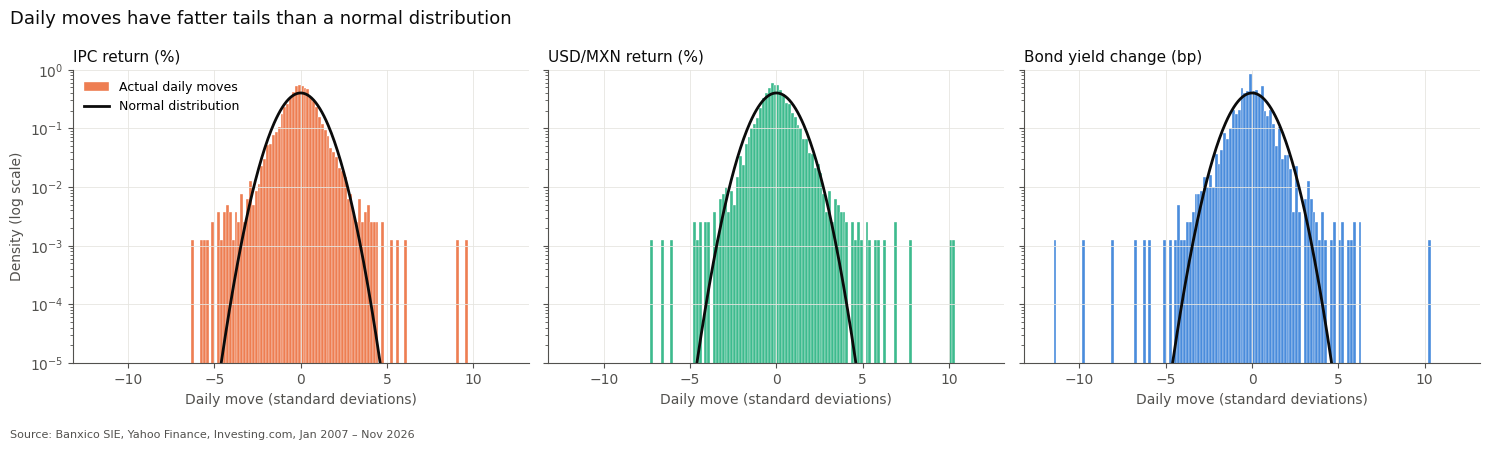

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
panel_colors = [COLORS["ipc"], COLORS["usd"], COLORS["bond"]]
x = np.linspace(-12, 12, 400)

for ax, (col, label), color in zip(axes, labels.items(), panel_colors):
    z = (factors[col] - factors[col].mean()) / factors[col].std()       # standardise
    ax.hist(z, bins=144, range=(-12, 12), density=True, color=color, alpha=0.85,
            edgecolor="white", linewidth=0.3, label="Actual daily moves")
    ax.plot(x, stats.norm.pdf(x), color=INK, linewidth=2, label="Normal distribution")
    ax.set_yscale("log")
    ax.set_ylim(1e-5, 1)
    ax.set_title(label, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("Daily move (standard deviations)")

axes[0].set_ylabel("Density (log scale)")
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Daily moves have fatter tails than a normal distribution",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.text(0.01, -0.04, "Source: Banxico SIE, Yahoo Finance, Investing.com, Jan 2007 – Nov 2026",
         fontsize=8, color=MUTED)
plt.tight_layout()
plt.savefig("/content/images/fat_tails_distribution.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**Extreme days sit far outside what the normal curve allows**
- In all three panels the normal curve falls to almost zero beyond about ±4.5 standard deviations, yet actual daily moves reach about +9.7 and −6.2 standard deviations for the IPC, +10.2 and −7.2 for USD/MXN, and +10.3 and −11.4 for the bond yield.
- Under a normal distribution, a move of 6 standard deviations or more would essentially never happen in 20 years; here it occurs several times in every factor.
- The tails are uneven: the IPC and USD/MXN have longer right tails (big stock rallies and sharp peso sell-offs), while the bond yield has extreme moves in both directions.
- Implication: parametric VaR, which assumes the bell curve, is expected to underestimate the 99% loss. This is tested in the Section 3 backtest.

## 1.5 Correlations: calm vs crisis markets

**Correlation** measures how two factors move together (+1 = always same direction, −1 = always opposite, 0 = unrelated). It drives **diversification**: the less the portfolio legs lose at the same time, the lower the total risk.

The correlations are compared across three periods: the full history, calm periods (excluding the three crisis windows) and crisis periods only. A rolling 250-day (about one-year) correlation then shows how the relationships change over time.

**How to read the signs here:**
- **IPC vs USD/MXN negative** = stocks fall on the same days the peso weakens.
- **USD/MXN vs bond yield positive** = yields rise on the same days the peso weakens.
- **IPC vs bond yield negative** = stocks fall on the same days yields rise.
- In P&L terms: the bond and stock legs lose while the USD leg gains, which is the natural hedge.

In [ ]:
corr_names = {"ipc_ret": "IPC", "usdmxn_ret": "USD/MXN", "bond_dy_bp": "Bond yield Δ"}
f = factors.rename(columns=corr_names)

# Flag every day that falls inside one of the crisis windows
crisis_mask = pd.Series(False, index=f.index)
for start, end in CRISIS_WINDOWS.values():
    crisis_mask |= (f.index >= start) & (f.index <= end)

corr_tables = {
    "Full period":        f.corr(),
    "Calm (no crises)":   f[~crisis_mask].corr(),
    "Crisis windows":     f[crisis_mask].corr(),
}
pairs = [("IPC", "USD/MXN"), ("IPC", "Bond yield Δ"), ("USD/MXN", "Bond yield Δ")]

corr_compare = pd.DataFrame(
    {period: [c.loc[a, b] for a, b in pairs] for period, c in corr_tables.items()},
    index=[f"{a} vs {b}" for a, b in pairs]).round(2)

print(f"Days - full: {len(f)}, calm: {(~crisis_mask).sum()}, crisis: {crisis_mask.sum()}")
corr_compare

Days - full: 4850, calm: 4593, crisis: 257


,Full period,Calm (no crises),Crisis windows
IPC vs USD/MXN,-0.40,-0.35,-0.51
IPC vs Bond yield Δ,-0.24,-0.17,-0.44
USD/MXN vs Bond yield Δ,0.36,0.30,0.51


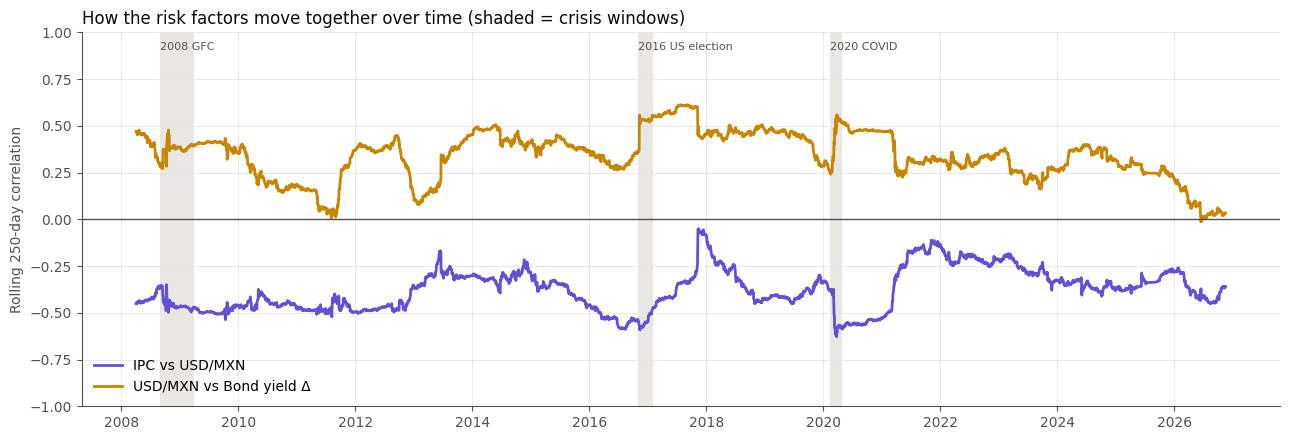

In [ ]:
# Rolling 1-year correlation of the two key pairs, with crisis windows shaded
roll = pd.DataFrame({
    "IPC vs USD/MXN":          f["IPC"].rolling(250).corr(f["USD/MXN"]),
    "USD/MXN vs Bond yield Δ": f["USD/MXN"].rolling(250).corr(f["Bond yield Δ"]),
}).dropna()

fig, ax = plt.subplots(figsize=(13, 4.5))
for name, (start, end) in CRISIS_WINDOWS.items():
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=GRID, alpha=0.9, lw=0)
    ax.text(pd.Timestamp(start), 0.95, name, fontsize=8, color=MUTED, va="top")

line_colors = {"IPC vs USD/MXN": "#6250d6", "USD/MXN vs Bond yield Δ": "#c98500"}
for col in roll:
    ax.plot(roll.index, roll[col], color=line_colors[col], linewidth=2, label=col)

ax.axhline(0, color=MUTED, linewidth=1)
ax.set_ylim(-1, 1)
ax.set_ylabel("Rolling 250-day correlation")
ax.set_title("How the risk factors move together over time (shaded = crisis windows)",
             loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig("/content/images/rolling_correlation.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**Correlations strengthen in crises, so the stock and bond legs lose together while the USD leg hedges**
- IPC vs USD/MXN: −0.35 in calm markets vs −0.51 in crises (−0.40 overall). Stocks fall on the days the peso weakens, and more strongly under stress.
- USD/MXN vs bond yield: 0.30 calm vs 0.51 crisis (0.36 overall). Bond yields rise on the days the peso weakens.
- IPC vs bond yield: −0.17 calm vs −0.44 crisis (−0.24 overall). In crises stocks fall on the same days yields rise, so the **bond and IPC legs lose money together**; this link more than doubles under stress.
- Comparison based on 4,593 calm days and 257 crisis days.
- The rolling chart shows sudden jumps at the 2016 US election and COVID: USD/MXN vs bond yield rose to about 0.55, and IPC vs USD/MXN fell to about −0.6 in March 2020.
- Since 2025, the USD/MXN vs bond yield correlation has fallen to about 0, its lowest level in the data, so the peso and bond yields have recently moved almost independently.

## 1.6 Bond duration and convexity

The data has the bond **yield**, but the portfolio's profit or loss depends on the bond **price**. They move in opposite directions: when yields rise, existing bonds with lower coupons become less attractive, so their price falls.

Two measures convert a yield change into a price change:
- **Modified duration:** the approximate % price change for a 1 percentage-point (100 bp) change in yield. Duration of 7 → a +1% yield move ≈ −7% price.
- **Convexity:** a correction for large yield moves, because the price-yield relationship is curved, not straight.

**Formula:** price change % ≈ −Duration × Δyield + ½ × Convexity × Δyield²

The bond is modelled as a **10-year par bond** (coupon = current yield, paid twice a year), and duration and convexity are recalculated each day from that day's yield. The approximation is then checked against an exact repricing for 25, 100 and 300 bp shocks. The 300 bp shock is the size used later in the Banxico stress scenario.

In [ ]:
def bond_cashflows(coupon_pct, maturity=BOND_MATURITY_YEARS, freq=COUPONS_PER_YEAR):
    """Cash-flow times (years) and amounts per 100 face value."""
    n = maturity * freq
    t = np.arange(1, n + 1) / freq             # 0.5, 1.0, ..., 10.0 years
    cf = np.full(n, coupon_pct / freq)         # semi-annual coupon
    cf[-1] += 100                              # face value repaid at maturity
    return t, cf

def bond_price(coupon_pct, yield_pct, maturity=BOND_MATURITY_YEARS, freq=COUPONS_PER_YEAR):
    """Exact price: present value of all cash flows at the given yield."""
    t, cf = bond_cashflows(coupon_pct, maturity, freq)
    return (cf / (1 + yield_pct / 100 / freq) ** (t * freq)).sum()

def bond_risk(yield_pct, maturity=BOND_MATURITY_YEARS, freq=COUPONS_PER_YEAR):
    """Price, Macaulay duration, modified duration and convexity of a par bond."""
    y = yield_pct / 100
    t, cf = bond_cashflows(yield_pct, maturity, freq)     # par bond: coupon = yield
    pv = cf * (1 + y / freq) ** (-t * freq)               # present value of each cash flow
    price = pv.sum()
    mac_duration = (t * pv).sum() / price                 # weighted-average time to cash flows (years)
    mod_duration = mac_duration / (1 + y / freq)          # % price sensitivity to yield
    convexity = (pv * t * (t + 1 / freq)).sum() / (price * (1 + y / freq) ** 2)
    return pd.Series({"price": price, "mac_duration": mac_duration,
                      "mod_duration": mod_duration, "convexity": convexity})

# Duration and convexity for every day (based on that day's yield)
bond_risk_daily = market["mbono10y"].apply(bond_risk)

print("Latest yield:", market["mbono10y"].iloc[-1], "%")
display(bond_risk_daily.iloc[[-1]].round(3))
display(bond_risk_daily[["mod_duration", "convexity"]].describe().loc[["min", "mean", "max"]].round(3))

Latest yield: 9.3 %


,price,mac_duration,mod_duration,convexity
date,,,,
2026-11-17,100.0,6.719,6.42,55.271


,mod_duration,convexity
min,6.000,49.889
mean,6.997,62.895
max,8.012,76.632


In [ ]:
# Validation: how accurate is the duration-convexity approximation vs exact repricing?
y0 = market["mbono10y"].iloc[-1]
r0 = bond_risk(y0)

rows = []
for bp in [25, 100, 300]:
    dy = bp / 10_000                                          # bp -> decimal
    approx = -r0["mod_duration"] * dy + 0.5 * r0["convexity"] * dy**2
    rows.append({
        "yield_shock_bp":          bp,
        "duration_only_%":         -r0["mod_duration"] * dy * 100,
        "duration_+_convexity_%":  approx * 100,
        "exact_reprice_%":         (bond_price(y0, y0 + bp / 100) / r0["price"] - 1) * 100,
        "loss_on_40M_position_MXN_m": approx * POSITIONS["bond"] / 1e6,
    })
approx_check = pd.DataFrame(rows).set_index("yield_shock_bp")
approx_check["error_vs_exact_pp"] = approx_check["duration_+_convexity_%"] - approx_check["exact_reprice_%"]
approx_check.round(3)

,duration_only_%,duration_+_convexity_%,exact_reprice_%,loss_on_40M_position_MXN_m,error_vs_exact_pp
yield_shock_bp,,,,,
25,-1.605,-1.588,-1.588,-0.635,0.000
100,-6.420,-6.144,-6.153,-2.458,0.009
300,-19.261,-16.774,-16.997,-6.709,0.224


**Finding:**

**A 1 percentage-point rise in yield cuts the bond's value by about 6.1% (≈ MXN 2.46M on the MXN 40M position)**
- At the latest yield of 9.3%, the 10-year bond has a modified duration of 6.42 and convexity of 55.27. Over 2007–2026, duration ranged from 6.00 to 8.01 (average 7.00); it is lower when yields are high, because higher coupons return cash sooner.
- For a 100 bp rise, duration + convexity estimates −6.144% vs −6.153% from exact repricing (error 0.009 pp).
- For a 300 bp rise: duration alone estimates −19.26%, duration + convexity −16.77% and exact repricing −17.00% (error 0.224 pp). The approximation is accurate enough for daily P&L and the Banxico stress scenario, while duration alone would overstate the loss by about 2.3 pp.

## 1.7 Daily portfolio P&L

This step combines everything into the **daily profit/loss in MXN** for each leg and the total portfolio:
- **IPC leg** = MXN 30M × IPC return
- **USD leg** = MXN 30M × USD/MXN return (a weaker peso = **gain**)
- **Bond leg** = MXN 40M × (−duration × Δyield + ½ × convexity × Δyield²), using the duration at the **start** of each day

**Diversification benefit** compares the total portfolio's volatility with the sum of the three legs' volatilities. If the legs never offset each other, the two would be equal; the gap is the risk saved by holding all three together.

*Simplification:* only price moves are included. Bond coupon income (carry) is ignored, which is standard for 1–10 day risk measures.

In [ ]:
dy = factors["bond_dy_bp"] / 10_000                            # yield change as a decimal
start_of_day = bond_risk_daily.shift(1).loc[factors.index]     # duration known at the start of each day
bond_ret = -start_of_day["mod_duration"] * dy + 0.5 * start_of_day["convexity"] * dy**2

pnl = pd.DataFrame({
    "bond": POSITIONS["bond"] * bond_ret,
    "ipc":  POSITIONS["ipc"]  * factors["ipc_ret"],
    "usd":  POSITIONS["usd"]  * factors["usdmxn_ret"],
}).dropna()
pnl["total"] = pnl[["bond", "ipc", "usd"]].sum(axis=1)

# Summary per leg (in MXN millions)
pnl_m = pnl / 1e6
pnl_summary = pd.DataFrame({
    "daily_std_MXN_m":  pnl_m.std(),
    "worst_day_MXN_m":  pnl_m.min(),
    "worst_day_date":   pnl_m.idxmin().dt.date,
    "best_day_MXN_m":   pnl_m.max(),
    "share_of_losing_days_%": (pnl_m < 0).mean() * 100,
}).round(3)
display(pnl_summary)

# Diversification: total risk vs the sum of each leg's risk on its own
sum_of_legs = pnl_m[["bond", "ipc", "usd"]].std().sum()
portfolio = pnl_m["total"].std()
print(f"Sum of standalone daily std: MXN {sum_of_legs:.3f}M")
print(f"Portfolio daily std:         MXN {portfolio:.3f}M")
print(f"Diversification benefit:     {(1 - portfolio / sum_of_legs) * 100:.1f}% less risk")

,daily_std_MXN_m,worst_day_MXN_m,worst_day_date,best_day_MXN_m,share_of_losing_days_%
bond,0.217,-1.967,2008-10-22,2.303,46.598
ipc,0.341,-2.103,2008-10-22,3.302,48.515
usd,0.225,-1.633,2008-10-13,2.295,52.309
total,0.391,-3.073,2008-10-22,5.533,48.948


Sum of standalone daily std: MXN 0.782M
Portfolio daily std:         MXN 0.391M
Diversification benefit:     50.0% less risk


In [ ]:
# The 10 worst portfolio days, broken down by leg: does the USD leg offset the losses?
worst10 = pnl_m.nsmallest(10, "total").round(2)
worst10["usd_leg_gained"] = worst10["usd"] > 0
worst10.index = worst10.index.date
print("Days where the USD leg gained:", int(worst10["usd_leg_gained"].sum()), "of 10")
worst10

Days where the USD leg gained: 7 of 10


,bond,ipc,usd,total,usd_leg_gained
2008-10-22,-1.97,-2.10,1.00,-3.07,True
2008-10-23,-0.65,-1.58,-0.13,-2.35,False
2008-11-12,-0.82,-1.50,0.23,-2.09,True
2008-10-09,0.03,-0.53,-1.38,-1.88,False
2018-11-08,-0.39,-1.74,0.33,-1.81,True
2018-10-29,-1.00,-1.26,0.50,-1.76,True
2008-09-29,-0.24,-1.92,0.41,-1.75,True
2020-03-11,-1.29,-0.67,0.27,-1.70,True
2008-10-24,-0.07,-1.38,-0.23,-1.68,False
2011-08-08,-0.32,-1.74,0.51,-1.55,True


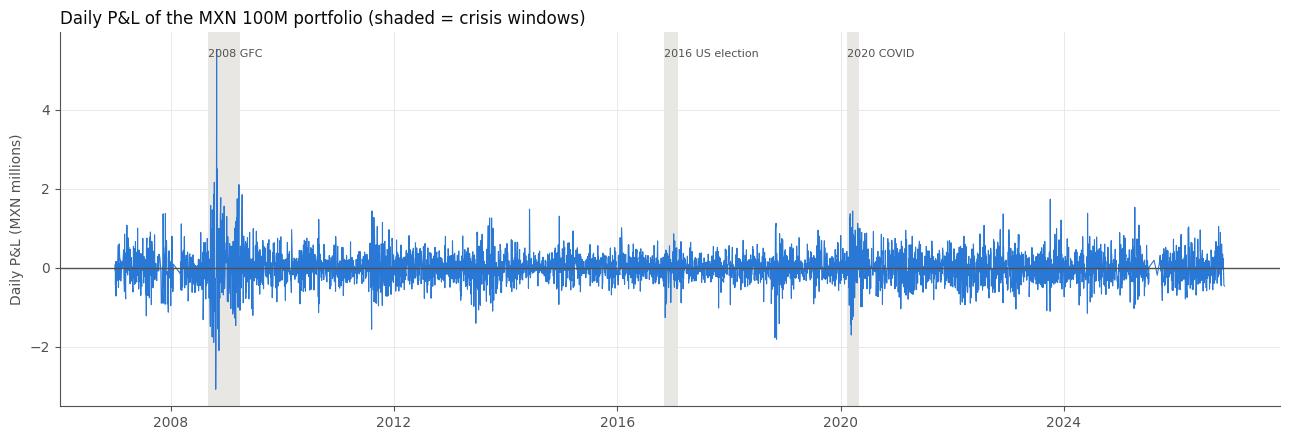

In [ ]:
# Daily total P&L over time, with crisis windows shaded
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, (start, end) in CRISIS_WINDOWS.items():
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=GRID, alpha=0.9, lw=0)
    ax.text(pd.Timestamp(start), pnl_m["total"].max(), name, fontsize=8, color=MUTED, va="top")

ax.plot(pnl_m.index, pnl_m["total"], color=COLORS["bond"], linewidth=0.8)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_ylabel("Daily P&L (MXN millions)")
ax.set_title("Daily P&L of the MXN 100M portfolio (shaded = crisis windows)",
             loc="left", color=INK, fontsize=12)
plt.tight_layout()
plt.savefig("/content/images/daily_pnl.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

# Save outputs for the next sections / notebooks
factors.to_csv("/content/factors.csv")
pnl.to_csv("/content/portfolio_pnl.csv")
bond_risk_daily.to_csv("/content/bond_risk_daily.csv")

**Finding:**

**Holding the three assets together halves daily risk (−50.0%), and the USD leg gained on 7 of the 10 worst days**
- Daily P&L volatility: bond MXN 0.217M, IPC MXN 0.341M, USD MXN 0.225M, total portfolio MXN 0.391M. The IPC position is the most volatile single leg.
- The three legs' standalone volatilities add up to MXN 0.782M vs MXN 0.391M for the portfolio, a diversification benefit of 50.0%.
- The worst portfolio day was 22 Oct 2008: −MXN 3.07M (bond −1.97M, IPC −2.10M, partly offset by USD +1.00M). It was also the worst day for both the bond and IPC legs.
- The USD leg gained on 7 of the 10 worst days. The exceptions were 9, 23 and 24 Oct 2008. On 9 Oct the peso strengthened sharply and the USD leg lost MXN 1.38M, so the hedge does not work every day.
- 7 of the 10 worst days fall in the crisis windows (6 in the 2008 GFC, 1 in COVID). Three are outside them: 8 Aug 2011 (after the US credit rating downgrade) and 29 Oct and 8 Nov 2018 (a domestic Mexican political sell-off), so large losses can also come from events outside major global crises.
- The P&L chart shows losses clustering in late 2008, with smaller bursts in 2011, late 2018 and March 2020. During the 2016 US election window the portfolio's swings stayed small despite the largest peso move in the data, consistent with the USD leg offsetting the other two.

**Summary - Section 1: Risk Factor Analysis and Portfolio P&L**

**Key results**
- All three risk factors have **fat tails**: excess kurtosis of 6.89 (IPC), 9.90 (USD/MXN) and 12.85 (bond yield), with 71, 70 and 77 days beyond 3 standard deviations vs about 13.1 expected under a normal distribution. Normality is rejected for all three.
- Correlations **strengthen in crises**: IPC vs USD/MXN moves from −0.35 (calm) to −0.51 (crisis), USD/MXN vs bond yield from 0.30 to 0.51, and IPC vs bond yield from −0.17 to −0.44.
- The 10-year M Bono has a modified duration of 6.42 at a 9.3% yield; a 100 bp rise lowers its value by about 6.1% (≈ MXN 2.46M on the bond position). The duration-convexity approximation is within 0.224 pp of exact repricing even for a 300 bp shock.
- Diversification cuts daily portfolio risk by **50.0%** (MXN 0.391M vs MXN 0.782M). The USD position gained on 7 of the 10 worst days, acting as a natural hedge.
- The worst day was 22 Oct 2008 (−MXN 3.07M). Most large losses cluster in the 2008 crisis, but three of the 10 worst days came from events outside the crisis windows (Aug 2011 and Oct–Nov 2018).

**Business implications**
1. A risk model that assumes normal returns (parametric VaR) is likely to understate rare, large losses, so limits based on it alone could be set too loosely.
2. Diversification weakens when it is needed most: in crises the bond and stock positions lose on the same days (correlation −0.17 → −0.44), so risk estimates based on calm-period correlations would be too optimistic.
3. The USD position is a deliberate risk reducer, not just a currency bet. Reducing it would likely increase crisis losses, although it can also lose on days the peso rebounds sharply (e.g., 9 Oct 2008).
4. The peso-bond link has weakened since 2025 (rolling correlation near 0), so the USD position may protect the bond leg less in the next sell-off than it did historically.
5. Because volatility comes in bursts, a model using a long-run average volatility will react slowly when markets turn.

**Recommendations for next steps**
- *Insight:* returns are fat-tailed and not normally distributed. → *Recommendation:* in Section 2, calculate VaR with all three methods (historical, parametric, Monte Carlo) and add Expected Shortfall, to measure how much the normal assumption understates tail losses.
- *Insight:* volatility and correlations change over time and jump in crises. → *Recommendation:* use a rolling 250-day window for VaR and test in Section 3 (backtesting) whether each method reacts quickly enough when markets turn.
- *Insight:* the worst losses cluster in crisis periods, but some come from local or non-crisis events. → *Recommendation:* in Section 4, replay the 2008, 2016 and 2020 crises on today's portfolio, and consider adding the Oct–Nov 2018 domestic sell-off as a fourth historical scenario.

**Limitations**
- The bond is modelled as a generic 10-year par bond; real holdings have specific coupons and maturities.
- P&L covers price changes only; bond coupon income (carry) is excluded.
- Weights are held fixed (daily rebalancing assumed).
- The midday FIX timing slightly understates the same-day IPC vs USD/MXN correlation, so the diversification benefit may be slightly overstated.

# Section 2 - Value at Risk (VaR) and Expected Shortfall (ES)



**Objective:** Estimate how much the MXN 100M portfolio could lose on a normal bad day, using three standard methods, and compare them with a daily risk limit.

**Key terms**
- **Value at Risk (VaR):** the loss that should only be exceeded on a small share of days. *1-day 99% VaR = MXN 1M* means: on 99 days out of 100, the portfolio should not lose more than MXN 1M.
- **Expected Shortfall (ES):** the **average** loss on the days that are worse than VaR, i.e., how bad the bad days are. Basel regulations now prefer ES because VaR says nothing about losses beyond the cutoff.
- **Confidence level:** 95% looks at a 1-in-20 bad day, 99% at a 1-in-100 bad day.
- **Horizon:** 1-day VaR is used for daily trading limits; 10-day VaR is the regulatory holding period (the time assumed to sell or hedge positions in a stressed market).
- **Risk limit:** the maximum 1-day 99% VaR the portfolio is allowed to run (set here at MXN 1.5M, i.e., 1.5% of the portfolio).

## 2.1 Setup



This step sets the parameters used throughout Sections 2–4: the confidence levels, the lookback window, the 10-day horizon, the risk limit and the number of Monte Carlo simulations.

**Lookback window:** VaR is calculated from the **last 250 trading days** (about one year), as required by Basel. This measures the portfolio's **current** risk. The full 2007–2026 history is also shown for comparison, because a calm recent year can make risk look smaller than it is over a full market cycle.

In [ ]:
CONF_LEVELS = [0.95, 0.99]      # confidence levels: 95% = 1-in-20 bad day, 99% = 1-in-100 bad day
WINDOW      = 250               # lookback window = about 1 trading year
HORIZON     = 10                # regulatory holding period in days (Basel)
RISK_LIMIT  = 1_500_000         # daily 99% VaR limit: MXN 1.5M (1.5% of the portfolio)
N_SIMS      = 10_000            # number of simulated days for Monte Carlo
rng = np.random.default_rng(42) # fixed seed so the simulation gives the same result every run

legs = ["bond", "ipc", "usd"]
pnl_window     = pnl.iloc[-WINDOW:]                    # last 250 days of P&L = "current" risk
factors_window = factors.loc[pnl_window.index]         # matching risk-factor changes

print(f"Current window: {pnl_window.index.min().date()} to {pnl_window.index.max().date()} ({len(pnl_window)} days)")
print(f"Full history:   {pnl.index.min().date()} to {pnl.index.max().date()} ({len(pnl)} days)")
print(f"Risk limit:     MXN {RISK_LIMIT/1e6:.1f}M daily 99% VaR")

Current window: 2025-11-18 to 2026-11-17 (250 days)
Full history:   2007-01-03 to 2026-11-17 (4850 days)
Risk limit:     MXN 1.5M daily 99% VaR


**Outcome:** The current VaR window covers the last 250 trading days, from 18 Nov 2025 to 17 Nov 2026. The full history covers 4,850 daily observations from 3 Jan 2007 to 17 Nov 2026. The risk limit is set at MXN 1.5M of 1-day 99% VaR (1.5% of the portfolio).

## 2.2 Historical VaR and ES



**Idea:** "Tomorrow will look like one of the days we have already seen."

1. Take the portfolio's actual daily P&L over the window.
2. Sort the days from worst to best.
3. **VaR** = the loss at the cutoff: the 5% worst day (95%) or the 1% worst day (99%).
4. **ES** = the average of all losses at or beyond that cutoff.

**Strength:** no assumptions about the shape of returns; real crashes and fat tails are included automatically.
**Weakness:** it only knows the days in the window. With 250 days, the 99% VaR rests on just 2–3 worst days, so it is sensitive to which days happen to be in the window.

**ES-to-VaR ratio:** how much worse the average bad day is than the cutoff. A higher ratio means fatter tails.

In [ ]:
def hist_var_es(pnl_series, cl):
    """Historical VaR and ES (as positive MXN losses) at confidence level cl."""
    losses = -pnl_series                                  # losses as positive numbers
    var = np.quantile(losses, cl)                         # loss exceeded on only (1 - cl) of days
    es = losses[losses >= var].mean()                     # average loss on those worst days
    return var, es

rows = []
for label, data in [("Last 250 days", pnl_window["total"]), ("Full history", pnl["total"])]:
    for cl in CONF_LEVELS:
        var, es = hist_var_es(data, cl)
        rows.append({"window": label, "confidence": f"{cl:.0%}",
                     "VaR_MXN_m": var / 1e6, "ES_MXN_m": es / 1e6,
                     "ES_to_VaR": es / var,                           # how much worse the tail is than the cutoff
                     "worst_days_used": int((-data >= var).sum())})   # number of days behind the ES figure
hist_table = pd.DataFrame(rows)
hist_table.round(3)

,window,confidence,VaR_MXN_m,ES_MXN_m,ES_to_VaR,worst_days_used
0,Last 250 days,95%,0.544,0.620,1.140,13
1,Last 250 days,99%,0.691,0.742,1.073,3
2,Full history,95%,0.567,0.848,1.497,243
3,Full history,99%,0.958,1.331,1.390,49


**Finding:**

**The past year has been calmer than the long-run average: current 99% VaR is MXN 0.69M, vs MXN 0.96M over the full history**
- Last 250 days: 1-day VaR is MXN 0.544M at 95% and MXN 0.691M at 99%; ES is MXN 0.620M and MXN 0.742M.
- Full history (2007–2026): 1-day VaR is MXN 0.567M at 95% and MXN 0.958M at 99%; ES is MXN 0.848M and MXN 1.331M.
- The gap is largest in the tail. At 95% the two windows are similar (0.544 vs 0.567), but the 99% ES over the full history (MXN 1.331M) is much higher than in the last year (MXN 0.742M), because the full history includes crisis days such as Oct 2008.
- The ES-to-VaR ratio is only 1.07 at 99% in the last year vs 1.39 over the full history: recent bad days have been close to the cutoff, while historically the worst days went far beyond it.
- The current 99% figures rest on just 3 days (vs 49 over the full history), so they are sensitive to which days happen to fall in the window.

## 2.3 Parametric (variance-covariance) VaR and ES



**Idea:** "Daily P&L follows a normal bell curve." VaR then comes from a formula instead of sorting days:
- **VaR = z × σ − μ**, where **σ** is the portfolio's daily volatility, **μ** its average daily P&L and **z** the number of standard deviations for the confidence level (1.645 at 95%, 2.326 at 99%).
- **ES = σ × φ(z) / (1 − confidence) − μ**, the average loss beyond VaR under a normal curve (φ = normal density).

**How the portfolio volatility is built:** σ comes from the **covariance matrix** of the three legs (how much each leg moves, and how they move together). This is where diversification enters: negative covariances (e.g., the USD leg gaining when the others lose) reduce σ. As a check, it should equal the volatility of the total P&L.

**Strength:** simple, fast and easy to explain; shows clearly how correlations drive risk.
**Weakness:** Section 1 showed the returns are **not normal** (fat tails), so this method is expected to understate the 99% loss.

In [ ]:
z = {cl: stats.norm.ppf(cl) for cl in CONF_LEVELS}       # z-score: 1.645 at 95%, 2.326 at 99%

cov = pnl_window[legs].cov()                              # covariance matrix of the three legs (MXN^2)
ones = np.ones(len(legs))                                 # each leg's P&L counts once in the total
sigma_p = np.sqrt(ones @ cov.values @ ones)               # portfolio volatility from the covariance matrix
mu_p = pnl_window["total"].mean()                         # average daily P&L

print(f"Portfolio daily volatility (from covariance matrix): MXN {sigma_p/1e6:.3f}M")
print(f"Check - std of total P&L directly:                   MXN {pnl_window['total'].std()/1e6:.3f}M")
print("\nCorrelation between the legs' P&L (last 250 days):")
display(pnl_window[legs].corr().round(2))

rows = []
for cl in CONF_LEVELS:
    var = z[cl] * sigma_p - mu_p
    es = sigma_p * stats.norm.pdf(z[cl]) / (1 - cl) - mu_p   # average loss beyond VaR under a normal curve
    rows.append({"confidence": f"{cl:.0%}", "z_score": z[cl],
                 "VaR_MXN_m": var / 1e6, "ES_MXN_m": es / 1e6})
param_table = pd.DataFrame(rows)
param_table.round(3)

Portfolio daily volatility (from covariance matrix): MXN 0.352M
Check - std of total P&L directly:                   MXN 0.352M

Correlation between the legs' P&L (last 250 days):


,bond,ipc,usd
bond,1.00,0.08,-0.03
ipc,0.08,1.00,-0.36
usd,-0.03,-0.36,1.00


,confidence,z_score,VaR_MXN_m,ES_MXN_m
0,95%,1.645,0.566,0.713
1,99%,2.326,0.806,0.925


**Finding:**

**The normal-distribution formula gives a 99% VaR of MXN 0.81M, higher than historical VaR for the past year**
- Portfolio daily volatility is MXN 0.352M, both from the covariance matrix and directly from the total P&L, confirming the calculation.
- Over the last year, the IPC and USD legs are clearly negatively correlated (−0.36), while the bond leg is almost uncorrelated with both the IPC (0.08) and USD (−0.03) legs. The USD position currently offsets stock losses but provides almost no hedge for the bond position.
- Parametric VaR is MXN 0.566M at 95% and MXN 0.806M at 99%; ES is MXN 0.713M and MXN 0.925M.
- At 99%, parametric VaR (MXN 0.806M) is higher than historical VaR (MXN 0.691M) for the same window, because the past year had no extreme days: the actual worst days were milder than a normal curve with the same volatility would predict. This is the opposite of the long-run pattern, where fat tails make the normal model **understate** risk (full-history 99% VaR: MXN 0.958M).

## 2.4 Monte Carlo VaR and ES



**Idea:** "Simulate 10,000 possible tomorrows and see how bad the worst ones are."

1. Measure the average and covariance of the three **risk factors** (IPC return, USD/MXN return, bond yield change) over the last 250 days.
2. Generate 10,000 random days. **Cholesky decomposition** turns independent random numbers into correlated ones, so the simulated factors move together like the real ones (e.g., the peso weakening on the days stocks fall).
3. **Reprice the portfolio** in each simulated day, using today's bond duration and convexity for the bond leg.
4. Read VaR and ES from the 10,000 simulated P&Ls, the same way as historical VaR.

Two versions are run:
- **Normal:** random shocks from a bell curve (same assumption as parametric VaR).
- **Student-t:** same volatility and correlations, but with **fat tails**. The t-distribution's "degrees of freedom" is set to match the fat-tailedness (kurtosis) of the actual P&L: the lower the number, the more extreme days.

A check confirms the simulated correlations match the real ones.

In [ ]:
fcols = ["ipc_ret", "usdmxn_ret", "bond_dy_bp"]
mu_f  = factors_window[fcols].mean().values               # average daily change of each factor
cov_f = factors_window[fcols].cov().values                # covariance matrix of the factors
L = np.linalg.cholesky(cov_f)                             # Cholesky factor: cov_f = L @ L.T

# Bond risk measures at today's yield (used to reprice the bond in every scenario)
r_today = bond_risk(market["mbono10y"].iloc[-1])

def scenario_pnl(sim):
    """Convert simulated factor changes (N x 3) into portfolio P&L in MXN."""
    dy = sim[:, 2] / 10_000                               # bp -> decimal
    bond = POSITIONS["bond"] * (-r_today["mod_duration"] * dy + 0.5 * r_today["convexity"] * dy**2)
    ipc  = POSITIONS["ipc"] * sim[:, 0]
    usd  = POSITIONS["usd"] * sim[:, 1]
    return pd.DataFrame({"bond": bond, "ipc": ipc, "usd": usd, "total": bond + ipc + usd})

# (1) Normal Monte Carlo: correlated normal shocks
Z = rng.standard_normal((N_SIMS, 3))                      # independent standard normal shocks
sims_normal = mu_f + Z @ L.T                              # Cholesky makes them correlated like the real data

# (2) Student-t Monte Carlo: same correlations, but fat tails
excess_kurt = stats.kurtosis(pnl["total"])                # fat-tailedness of the full-history P&L
df_t = max(4 + 6 / excess_kurt, 4.1)                      # t degrees of freedom matching that kurtosis
W = rng.chisquare(df_t, size=(N_SIMS, 1))
sims_t = mu_f + (Z @ L.T) * np.sqrt((df_t - 2) / W)       # same volatility, fatter tails

mc_pnl = {"Monte Carlo (normal)": scenario_pnl(sims_normal),
          "Monte Carlo (Student-t)": scenario_pnl(sims_t)}

# Check: do the simulated factors reproduce the real correlations?
pairs_idx = np.triu_indices(3, 1)
check = pd.DataFrame({
    "real (last 250 days)": factors_window[fcols].corr().values[pairs_idx],
    "simulated (normal)":   np.corrcoef(sims_normal.T)[pairs_idx],
}, index=["IPC vs USD/MXN", "IPC vs bond yield", "USD/MXN vs bond yield"]).round(2)
print(f"Excess kurtosis of actual P&L: {excess_kurt:.2f}")
print(f"Student-t degrees of freedom:  {df_t:.2f} (lower = fatter tails)")
check

Excess kurtosis of actual P&L: 11.55
Student-t degrees of freedom:  4.52 (lower = fatter tails)


,real (last 250 days),simulated (normal)
IPC vs USD/MXN,-0.36,-0.36
IPC vs bond yield,-0.08,-0.07
USD/MXN vs bond yield,0.03,0.04


,method,confidence,VaR_MXN_m,ES_MXN_m,ES_to_VaR
0,Monte Carlo (normal),95%,0.557,0.702,1.260
1,Monte Carlo (normal),99%,0.790,0.923,1.169
2,Monte Carlo (Student-t),95%,0.520,0.796,1.530
3,Monte Carlo (Student-t),99%,0.940,1.320,1.404


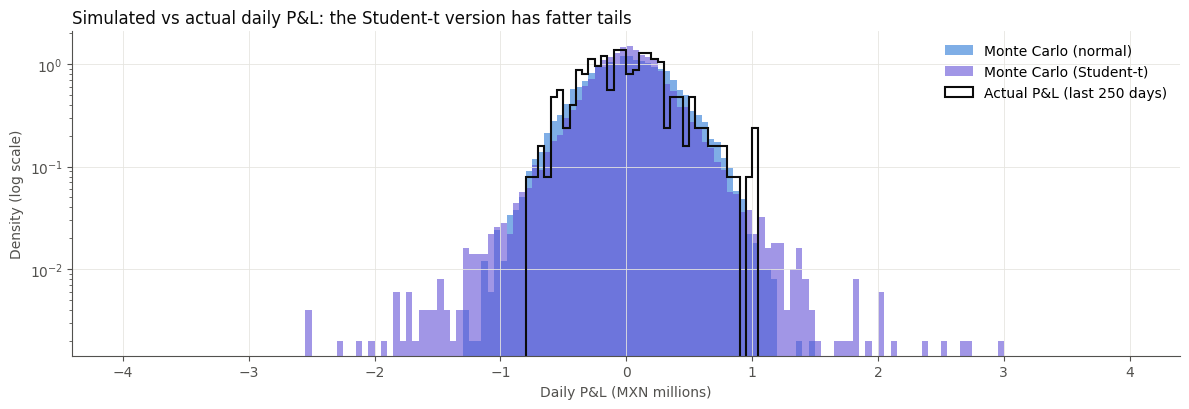

In [ ]:
rows = []
for name, sim in mc_pnl.items():
    for cl in CONF_LEVELS:
        var, es = hist_var_es(sim["total"], cl)           # same VaR/ES calculation, on simulated days
        rows.append({"method": name, "confidence": f"{cl:.0%}",
                     "VaR_MXN_m": var / 1e6, "ES_MXN_m": es / 1e6, "ES_to_VaR": es / var})
mc_table = pd.DataFrame(rows)
display(mc_table.round(3))

# Compare the simulated P&L distributions with the actual one (log scale shows the tails)
fig, ax = plt.subplots(figsize=(12, 4.2))
bins = np.linspace(-4, 4, 161)
ax.hist(mc_pnl["Monte Carlo (normal)"]["total"] / 1e6, bins=bins, density=True, alpha=0.6,
        color="#2a78d6", label="Monte Carlo (normal)")
ax.hist(mc_pnl["Monte Carlo (Student-t)"]["total"] / 1e6, bins=bins, density=True, alpha=0.6,
        color="#6250d6", label="Monte Carlo (Student-t)")
ax.hist(pnl_window["total"] / 1e6, bins=bins, density=True, histtype="step", linewidth=1.5,
        color=INK, label="Actual P&L (last 250 days)")
ax.set_yscale("log")
ax.set_xlabel("Daily P&L (MXN millions)")
ax.set_ylabel("Density (log scale)")
ax.set_title("Simulated vs actual daily P&L: the Student-t version has fatter tails",
             loc="left", color=INK, fontsize=12)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Finding:**

**Adding fat tails (Student-t) raises 99% VaR to MXN 0.94M and ES to MXN 1.32M, close to the full-history historical figures**
- The actual P&L has an excess kurtosis of 11.55, which corresponds to a Student-t distribution with 4.52 degrees of freedom (very fat-tailed).
- The simulation reproduces the real correlations of the last 250 days (IPC vs USD/MXN: −0.36 real vs −0.36 simulated; IPC vs bond yield: −0.08 vs −0.07; USD/MXN vs bond yield: 0.03 vs 0.04).
- Monte Carlo (normal): 99% VaR MXN 0.790M and ES MXN 0.923M, almost identical to parametric VaR (MXN 0.806M and MXN 0.925M), as expected since both assume a normal distribution.
- Monte Carlo (Student-t): 99% VaR MXN 0.940M and ES MXN 1.320M, with an ES-to-VaR ratio of 1.40 vs 1.17 for the normal version. These are very close to the full-history historical figures (MXN 0.958M and MXN 1.331M), so the Student-t model captures long-run tail risk using only the current year's volatility.
- At 95%, the Student-t VaR is slightly **lower** (MXN 0.520M vs MXN 0.557M). Fat-tailed distributions have more calm days and more extreme days, but fewer moderate bad days.
- The chart shows the actual P&L of the last year stayed within about −MXN 0.8M to +MXN 1.0M, while the Student-t simulation produces losses beyond MXN 2M.

## 2.5 10-day VaR: square-root-of-time shortcut vs actual 10-day losses



Regulators use a **10-day** horizon. The common shortcut is:

**10-day VaR ≈ 1-day VaR × √10 (≈ × 3.16)**

This shortcut assumes each day is independent and normally distributed. In reality, bad days tend to come in clusters (as seen in Section 1), so losses can build up faster than √10 suggests.

To test it, this step builds **actual 10-day P&L** by adding up 10 consecutive daily P&Ls, and calculates historical VaR and ES from those 10-day results. Only windows covering **10 consecutive business days** are used; windows that cross a data gap are skipped.

**actual_vs_sqrt10** compares the two: above 1 means the shortcut **understates** 10-day risk.

In [ ]:
# Business-day position of each P&L date, so 10-day windows that cross a data gap can be excluded
bd_pos = pd.Series(fx_calendar.get_indexer(pnl.index), index=pnl.index)
pnl_10d = pnl["total"].rolling(HORIZON).sum()                         # P&L over 10 consecutive observations
valid_10d = (bd_pos - bd_pos.shift(HORIZON - 1)) == HORIZON - 1       # True only if they are 10 consecutive business days
pnl_10d = pnl_10d[valid_10d].dropna()

print(f"Valid 10-day windows: {len(pnl_10d)} (full history), "
      f"{len(pnl_10d.loc[pnl_window.index.min():])} (last 250 days)")

rows = []
for label, data_1d, data_10d in [("Last 250 days", pnl_window["total"], pnl_10d.loc[pnl_window.index.min():]),
                                 ("Full history",  pnl["total"],        pnl_10d)]:
    for cl in CONF_LEVELS:
        var_1d, _ = hist_var_es(data_1d, cl)
        var_10d, es_10d = hist_var_es(data_10d, cl)
        rows.append({"window": label, "confidence": f"{cl:.0%}",
                     "1d_VaR_MXN_m":         var_1d / 1e6,
                     "sqrt10_VaR_MXN_m":     var_1d * np.sqrt(HORIZON) / 1e6,   # shortcut: 1-day VaR x 3.16
                     "actual_10d_VaR_MXN_m": var_10d / 1e6,                     # from real 10-day P&L
                     "actual_10d_ES_MXN_m":  es_10d / 1e6,
                     "actual_vs_sqrt10":     var_10d / (var_1d * np.sqrt(HORIZON))})
tenday_table = pd.DataFrame(rows)
tenday_table.round(3)

Valid 10-day windows: 4630 (full history), 250 (last 250 days)


,window,confidence,1d_VaR_MXN_m,sqrt10_VaR_MXN_m,actual_10d_VaR_MXN_m,actual_10d_ES_MXN_m,actual_vs_sqrt10
0,Last 250 days,95%,0.544,1.721,1.592,2.297,0.925
1,Last 250 days,99%,0.691,2.186,2.906,3.138,1.329
2,Full history,95%,0.567,1.792,1.694,2.453,0.945
3,Full history,99%,0.958,3.028,2.825,3.781,0.933


**Finding:**

**The √10 shortcut works reasonably over the long run, but understated the past year's 10-day 99% VaR by about a third**
- 4,630 valid 10-day windows were available over the full history and 250 in the last year.
- Last 250 days, 99%: the √10 shortcut gives MXN 2.186M, while actual 10-day losses give MXN 2.906M (ratio 1.33), so the shortcut **understates** 10-day risk. Losing days in the past year tended to come in runs, so losses built up faster than √10 assumes.
- Full history, 99%: the shortcut gives MXN 3.028M vs MXN 2.825M actual (ratio 0.93), and at 95% MXN 1.792M vs MXN 1.694M (ratio 0.945). Over the long run the shortcut slightly **overstates** 10-day risk, as crisis periods alternated big down days with big rebound days (e.g., Oct 2008), which partly cancel out over 10 days.
- 10-day 99% ES is MXN 3.138M in the last year and MXN 3.781M over the full history, i.e., an average loss of 3–4% of the portfolio on the worst two-week periods.
- The last-year 10-day estimates are based on heavily overlapping windows (only about 25 independent 10-day periods), so they are less reliable than the full-history figures.

## 2.6 Comparison of methods



All four estimates (historical, parametric, Monte Carlo normal, Monte Carlo Student-t) are put side by side for the **last 250 days**, at 95% and 99%, with:
- **VaR_99_10d_sqrt10:** the 10-day 99% VaR using the √10 shortcut (regulatory horizon).
- **% of portfolio:** the 1-day 99% VaR as a share of the MXN 100M portfolio.
- **vs limit %:** the 1-day 99% VaR as a share of the MXN 1.5M risk limit. Above 100% = **limit breached**.

The chart compares the 1-day 99% VaR and ES of each method against the risk limit.

In [ ]:
summary_rows = []
def add_row(method, var95, es95, var99, es99):
    summary_rows.append({"method": method,
                         "VaR_95_1d": var95, "ES_95_1d": es95,
                         "VaR_99_1d": var99, "ES_99_1d": es99,
                         "VaR_99_10d_sqrt10": var99 * np.sqrt(HORIZON)})

h95, he95 = hist_var_es(pnl_window["total"], 0.95)
h99, he99 = hist_var_es(pnl_window["total"], 0.99)
add_row("Historical", h95, he95, h99, he99)

p = param_table.set_index("confidence")
add_row("Parametric (normal)", p.loc["95%", "VaR_MXN_m"] * 1e6, p.loc["95%", "ES_MXN_m"] * 1e6,
        p.loc["99%", "VaR_MXN_m"] * 1e6, p.loc["99%", "ES_MXN_m"] * 1e6)

for name, sim in mc_pnl.items():
    v95, e95 = hist_var_es(sim["total"], 0.95)
    v99, e99 = hist_var_es(sim["total"], 0.99)
    add_row(name, v95, e95, v99, e99)

var_summary = pd.DataFrame(summary_rows).set_index("method") / 1e6       # MXN millions
var_summary["VaR_99_1d_%_of_portfolio"] = var_summary["VaR_99_1d"] * 1e6 / PORTFOLIO_VALUE * 100
var_summary["VaR_99_1d_vs_limit_%"]     = var_summary["VaR_99_1d"] * 1e6 / RISK_LIMIT * 100
var_summary.round(3)

,VaR_95_1d,ES_95_1d,VaR_99_1d,ES_99_1d,VaR_99_10d_sqrt10,VaR_99_1d_%_of_portfolio,VaR_99_1d_vs_limit_%
method,,,,,,,
Historical,0.544,0.620,0.691,0.742,2.186,0.691,46.091
Parametric (normal),0.566,0.713,0.806,0.925,2.548,0.806,53.711
Monte Carlo (normal),0.557,0.702,0.790,0.923,2.497,0.790,52.640
Monte Carlo (Student-t),0.520,0.796,0.940,1.320,2.972,0.940,62.655


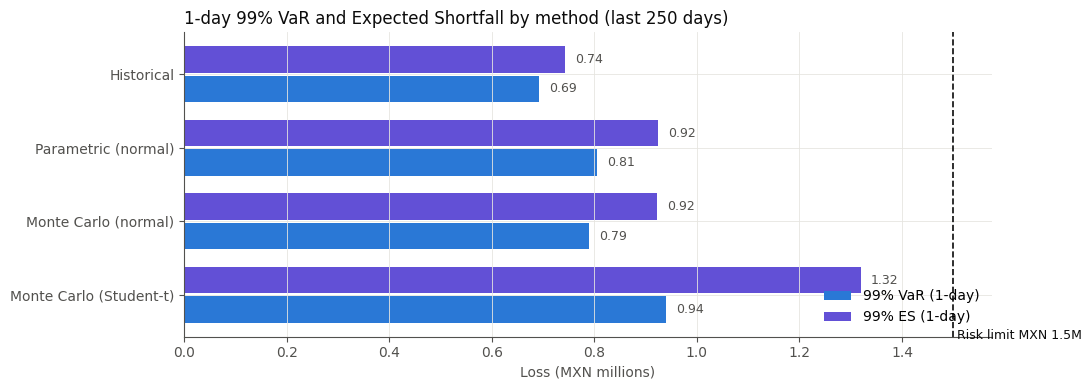

In [ ]:
methods = var_summary.index
y = np.arange(len(methods))
fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(y + 0.2, var_summary["VaR_99_1d"], height=0.36, color="#2a78d6", label="99% VaR (1-day)")
ax.barh(y - 0.2, var_summary["ES_99_1d"],  height=0.36, color="#6250d6", label="99% ES (1-day)")
for i, m in enumerate(methods):                                     # value labels at the end of each bar
    ax.text(var_summary.loc[m, "VaR_99_1d"] + 0.02, i + 0.2, f"{var_summary.loc[m, 'VaR_99_1d']:.2f}",
            va="center", fontsize=9, color=MUTED)
    ax.text(var_summary.loc[m, "ES_99_1d"] + 0.02, i - 0.2, f"{var_summary.loc[m, 'ES_99_1d']:.2f}",
            va="center", fontsize=9, color=MUTED)
ax.axvline(RISK_LIMIT / 1e6, color=INK, linestyle="--", linewidth=1.2)
ax.text(RISK_LIMIT / 1e6, len(methods) - 0.4, f" Risk limit MXN {RISK_LIMIT/1e6:.1f}M", fontsize=9, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(methods)
ax.invert_yaxis()
ax.set_xlabel("Loss (MXN millions)")
ax.set_title("1-day 99% VaR and Expected Shortfall by method (last 250 days)",
             loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("/content/images/var_es_by_method.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**All four methods put current 1-day 99% VaR between MXN 0.69M and 0.94M, well within the MXN 1.5M risk limit**
- 1-day 99% VaR by method: historical MXN 0.691M, parametric MXN 0.806M, Monte Carlo normal MXN 0.790M and Monte Carlo Student-t MXN 0.940M, i.e., 0.69%–0.94% of the portfolio.
- This uses 46%–63% of the MXN 1.5M limit. Even the highest 1-day 99% ES (Student-t, MXN 1.320M) stays below the limit.
- Historical VaR gives the lowest figure because the past year was calm; the Student-t Monte Carlo gives the highest because it adds the fat tails seen over 20 years.
- On the regulatory 10-day horizon (√10), 99% VaR ranges from MXN 2.186M (historical) to MXN 2.972M (Student-t).
- The spread between methods (MXN 0.25M at 99% VaR, MXN 0.58M at 99% ES) shows that the choice of model matters as much as the data: relying on historical VaR alone would show the lowest risk at a time when the tails are not represented in the window.

## 2.7 Risk contribution by leg



This step shows **where the portfolio's risk comes from**, using three measures at 99%:
- **Standalone VaR:** each leg's VaR as if it were held on its own. Their sum is what the risk would be with **no diversification**.
- **Component VaR (parametric):** each leg's share of the portfolio VaR, based on how much it moves **with** the total portfolio (z × covariance of the leg with the total ÷ portfolio volatility). The three components add up exactly to the portfolio VaR. A **negative** component means the leg **reduces** total risk (a hedge).
- **ES contribution (historical):** each leg's average loss on the portfolio's worst 1% of days, i.e., which leg actually lost money on the worst days.

The gap between the sum of standalone VaRs and the portfolio VaR is the **diversification benefit**.

Portfolio worst-1% days used for ES contribution: 3


,standalone_VaR_MXN_m,component_VaR_MXN_m,component_VaR_share_%,ES_contribution_MXN_m
bond,0.493,0.213,25.999,0.694
ipc,0.738,0.567,69.293,-0.010
usd,0.352,0.039,4.708,0.059
total,1.583,0.818,100.000,0.742


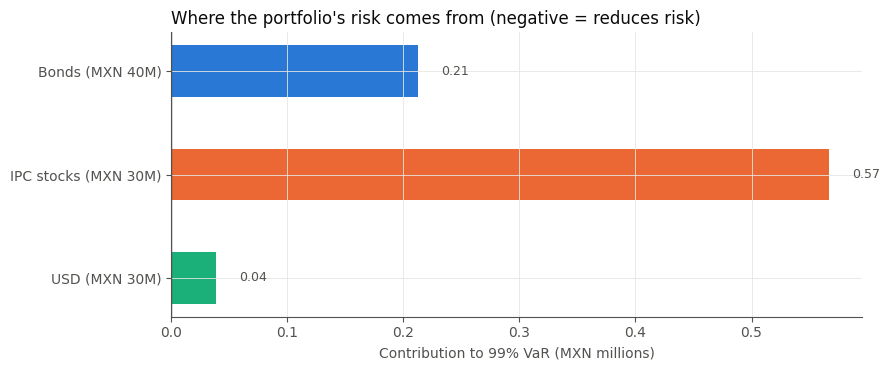

In [ ]:
cl = 0.99
sigma_total = pnl_window["total"].std()

# (1) Standalone VaR: each leg on its own
standalone = {leg: hist_var_es(pnl_window[leg], cl)[0] for leg in legs}

# (2) Parametric component VaR: z x covariance of the leg with the total / total volatility
component_param = {leg: z[cl] * pnl_window[leg].cov(pnl_window["total"]) / sigma_total for leg in legs}

# (3) Historical ES contribution: average loss of each leg on the portfolio's worst 1% days
var99_hist, _ = hist_var_es(pnl_window["total"], cl)
tail_days = pnl_window[-pnl_window["total"] >= var99_hist]
es_contrib = {leg: -tail_days[leg].mean() for leg in legs}

contrib = pd.DataFrame({
    "standalone_VaR_MXN_m":  pd.Series(standalone) / 1e6,
    "component_VaR_MXN_m":   pd.Series(component_param) / 1e6,
    "component_VaR_share_%": pd.Series(component_param) / sum(component_param.values()) * 100,
    "ES_contribution_MXN_m": pd.Series(es_contrib) / 1e6,
})
contrib.loc["total"] = [sum(standalone.values()) / 1e6, sum(component_param.values()) / 1e6,
                        100.0, sum(es_contrib.values()) / 1e6]
print(f"Portfolio worst-1% days used for ES contribution: {len(tail_days)}")
display(contrib.round(3))

# Bar chart: contribution of each leg to 99% VaR
fig, ax = plt.subplots(figsize=(9, 3.8))
vals = contrib.loc[legs, "component_VaR_MXN_m"]
ax.barh(legs, vals, color=[COLORS[l] for l in legs], height=0.5)
for i, v in enumerate(vals):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=MUTED)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(range(len(legs)))
ax.set_yticklabels(["Bonds (MXN 40M)", "IPC stocks (MXN 30M)", "USD (MXN 30M)"])
ax.invert_yaxis()
ax.set_xlabel("Contribution to 99% VaR (MXN millions)")
ax.set_title("Where the portfolio's risk comes from (negative = reduces risk)",
             loc="left", color=INK, fontsize=12)
plt.tight_layout()
plt.savefig("/content/images/risk_contribution.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**The IPC position drives 69% of the portfolio's risk with 30% of the capital, while the USD position adds almost no risk**
- Standalone 99% VaR: bond MXN 0.493M, IPC MXN 0.738M, USD MXN 0.352M. Held separately, they add up to MXN 1.583M; held together, the portfolio's component VaR is MXN 0.818M, about half, showing the strength of diversification.
- Component VaR: IPC MXN 0.567M (69.3%), bond MXN 0.213M (26.0%), USD MXN 0.039M (4.7%). The IPC leg is the dominant risk; the bond leg contributes less than its 40% capital share.
- The USD leg contributes only 4.7% of risk despite holding 30% of the capital and having a standalone VaR of MXN 0.352M. It offsets stock losses (correlation −0.36) but no longer hedges the bond leg, so its contribution is small but **positive** rather than negative.
- On the portfolio's 3 worst days of the past year, losses came almost entirely from the bond leg (MXN 0.694M on average), while the IPC was flat (−MXN 0.010M, i.e., a small gain) and the USD leg lost MXN 0.059M. The worst recent days were driven by interest-rate moves, not stock moves.
- The component VaRs sum to MXN 0.818M (= 2.326 × MXN 0.352M), slightly above the parametric VaR of MXN 0.806M, because the component split excludes the small average daily gain.

**Summary - Section 2: Value at Risk and Expected Shortfall**

**Key results**
- Current 1-day 99% VaR ranges from **MXN 0.69M (historical) to MXN 0.94M (Monte Carlo Student-t)**, i.e., 0.69%–0.94% of the MXN 100M portfolio, all within the MXN 1.5M risk limit. 1-day 99% ES ranges from MXN 0.74M to MXN 1.32M.
- The past year was calmer than the long run: historical 99% VaR is MXN 0.691M for the last 250 days vs MXN 0.958M over 2007–2026, and 99% ES is MXN 0.742M vs MXN 1.331M.
- Adding fat tails (Student-t, 4.52 degrees of freedom) raises 99% VaR to MXN 0.940M and ES to MXN 1.320M, close to the full-history historical figures.
- The √10 shortcut understated the past year's 10-day 99% VaR (MXN 2.186M vs MXN 2.906M actual), but slightly overstated it over the full history (MXN 3.028M vs MXN 2.825M).
- The IPC position drives 69.3% of portfolio risk with 30% of the capital; the bond position 26.0%; the USD position only 4.7%. Diversification roughly halves risk (MXN 1.583M standalone vs MXN 0.818M combined).

**Business implications**
1. The portfolio is currently well within its risk limit, but the low reading partly reflects a calm year. Historical VaR based only on the last 250 days would understate the risk the portfolio carries through a full market cycle.
2. The choice of VaR model matters: the gap between the lowest and highest 99% ES (MXN 0.58M) is almost as large as the VaR itself, so the model choice needs to be justified and tested, not assumed.
3. Stock market exposure is the main source of risk. Reducing the IPC position would cut portfolio VaR far more than reducing the bond or USD positions.
4. The USD position currently protects the portfolio against stock losses but not against bond losses, and the worst recent days were bond-driven. Interest-rate risk is less hedged now than it was historically.
5. Using the √10 rule for regulatory capital is not always conservative: when losses cluster, as in the past year, it can understate 10-day risk.

**Recommendations for next steps**
- *Insight:* the four methods give different answers, and the current window contains few extreme days. → *Recommendation:* in Section 3, backtest all four methods over 2008–2026 with a rolling 250-day window and count limit breaches, to see which one holds up through crises.
- *Insight:* the worst days in history (e.g., −MXN 3.07M on 22 Oct 2008) were far larger than any current VaR estimate. → *Recommendation:* in Section 4, stress test today's portfolio with the 2008, 2016 and 2020 crises and a Banxico +300 bp scenario, and compare the losses with VaR, ES and the MXN 1.5M limit.
- *Insight:* the √10 rule can understate 10-day risk. → *Recommendation:* report actual 10-day historical VaR alongside the √10 figure for regulatory purposes.

**Limitations**
- The 1-day 99% figures for the last 250 days rest on only 3 days, so they are statistically noisy.
- The Student-t degrees of freedom are estimated from the full-history P&L and assumed to apply today.
- Monte Carlo uses today's bond duration and convexity for all scenarios, and assumes the average and covariance of the last 250 days hold for tomorrow.
- The MXN 1.5M risk limit is an assumed figure for illustration, not a regulatory requirement.

# Section 3 - Backtesting: Can the VaR Model Be Trusted?



**Objective:** Test whether each VaR method would have worked in practice. For every day from 2008 to 2026, each method forecasts tomorrow's 99% VaR using only the data available at the time; the forecast is then compared with the loss that actually happened.

**Key terms**
- **Breach (exception):** a day when the actual loss was **bigger** than the VaR forecast.
- **Expected breaches:** a 99% VaR should be breached on about 1% of days (about 2–3 days a year); a 95% VaR on about 5% of days.
- **Too many breaches** → the model **underestimates** risk (dangerous: limits and capital are too low).
- **Too few breaches** → the model **overestimates** risk (safe but costly: capital is tied up unnecessarily).
- **No look-ahead:** each day's forecast only uses data up to the day before, exactly as a risk team would have had in real time.

## 3.1 Rolling VaR forecasts



For each day, every method calculates VaR from the **previous 250 days only**, then the window moves forward one day. Four methods are tested:

| Method | How it works | Expected behaviour |
|---|---|---|
| **Historical** | Actual 1%/5% worst P&L of the last 250 days | No distribution assumption, but slow to react: a crisis only enters the window as it happens |
| **Parametric (normal)** | z × volatility of the last 250 days | Assumes a bell curve, so it is likely to understate extreme losses |
| **Student-t** | Same volatility, but fat-tailed t-distribution (formula equivalent of the Section 2 Student-t Monte Carlo) | Allows for extreme days; degrees of freedom estimated from all data up to the previous day |
| **EWMA (normal)** | Volatility that gives **more weight to recent days** (RiskMetrics, λ = 0.94: yesterday gets 6% weight, older days less and less) | Reacts quickly when markets turn, the weakness flagged in Section 1 (volatility comes in bursts) |

The Monte Carlo methods from Section 2 are represented by their formula equivalents (parametric normal and Student-t), which gave almost the same results but are fast enough to run for every day over 18 years.

The backtest starts once 250 days of history are available (early 2008).

In [101]:

LAMBDA = 0.94                            # EWMA decay factor (RiskMetrics standard for daily data)
METHODS = ["Historical", "Parametric (normal)", "Student-t", "EWMA (normal)"]

total = pnl["total"]                     # daily portfolio P&L (MXN)
loss  = -total                           # daily loss (positive = money lost)

# Inputs for each forecast use ONLY data available before that day (.shift(1) = no look-ahead)
roll_mean = total.rolling(WINDOW).mean().shift(1)
roll_std  = total.rolling(WINDOW).std().shift(1)

# Student-t degrees of freedom from the kurtosis of all data up to the previous day
kurt_to_date = total.expanding(min_periods=WINDOW).kurt().shift(1)
df_roll = pd.Series(np.where(kurt_to_date > 0, 4 + 6 / kurt_to_date, 30),
                    index=total.index).clip(lower=4.1, upper=30)

# EWMA volatility: recent days get more weight (6% on yesterday, decaying by 0.94 each day further back)
ewma_std = np.sqrt((total ** 2).ewm(alpha=1 - LAMBDA, adjust=False).mean().shift(1))

forecasts = {}
for cl in CONF_LEVELS:
    z_cl = stats.norm.ppf(cl)
    t_scale = pd.Series(stats.t.ppf(cl, df_roll) * np.sqrt((df_roll - 2) / df_roll), index=total.index)
    forecasts[("Historical", cl)]          = -total.rolling(WINDOW).quantile(1 - cl).shift(1)
    forecasts[("Parametric (normal)", cl)] = z_cl * roll_std - roll_mean
    forecasts[("Student-t", cl)]           = t_scale * roll_std - roll_mean
    forecasts[("EWMA (normal)", cl)]       = z_cl * ewma_std

var_fc = pd.DataFrame(forecasts).dropna()                 # keep days where every method has a forecast
var_fc.columns.names = ["method", "confidence"]
loss_bt = loss.loc[var_fc.index]

print(f"Backtest period: {var_fc.index.min().date()} to {var_fc.index.max().date()} ({len(var_fc)} days)")
print("Last 5 days of 99% VaR forecasts (MXN millions):")
var_fc.xs(0.99, level="confidence", axis=1).tail().div(1e6).round(3)

Backtest period: 2008-04-04 to 2026-11-17 (4600 days)
Last 5 days of 99% VaR forecasts (MXN millions):


method,Historical,Parametric (normal),Student-t,EWMA (normal)
date,,,,
2026-11-10,0.691,0.809,0.916,0.824
2026-11-11,0.691,0.804,0.910,0.800
2026-11-12,0.691,0.804,0.910,0.780
2026-11-13,0.691,0.798,0.903,0.772
2026-11-17,0.691,0.801,0.907,0.789


**Outcome:** The backtest covers 4,600 trading days from 4 Apr 2008 to 17 Nov 2026. On the last day (17 Nov 2026), the four methods forecast a 1-day 99% VaR of MXN 0.691M (historical), MXN 0.801M (parametric), MXN 0.907M (Student-t) and MXN 0.789M (EWMA). The historical VaR stays flat at MXN 0.691M across the last five days because it only changes when an extreme day enters or leaves the 250-day window, while the other three move every day with volatility.

## 3.2 Breach counts and statistical tests

Each method's breaches are counted and compared with the expected number, and two standard statistical tests are applied:

- **Kupiec test (proportion of failures):** is the number of breaches consistent with the target rate (1% or 5%)? **p < 0.05 = too many or too few breaches** → the model fails.
- **Christoffersen test (independence):** do breaches **cluster**, i.e., is a breach more likely right after another breach? A good model should "learn" from a bad day and raise its VaR, so breaches should be spread out. **p < 0.05 = breaches cluster** → the model reacts too slowly.
- **Back-to-back breaches:** number of times a breach was followed by another breach the next day.

A method **passes** only if it passes both tests.

In [102]:
breaches = var_fc.lt(loss_bt, axis=0)                     # True when the actual loss is bigger than the VaR forecast

def kupiec_pof(x, n, p):
    """Kupiec proportion-of-failures test: is the breach rate consistent with the expected rate p?"""
    phat = x / n
    ll_expected = xlogy(n - x, 1 - p) + xlogy(x, p)
    ll_observed = xlogy(n - x, 1 - phat) + xlogy(x, phat)
    lr = -2 * (ll_expected - ll_observed)
    return lr, stats.chi2.sf(lr, df=1)

def christoffersen_ind(b):
    """Christoffersen independence test: is a breach more likely right after a breach?"""
    b = b.astype(int).values
    prev, curr = b[:-1], b[1:]
    n00 = int(((prev == 0) & (curr == 0)).sum()); n01 = int(((prev == 0) & (curr == 1)).sum())
    n10 = int(((prev == 1) & (curr == 0)).sum()); n11 = int(((prev == 1) & (curr == 1)).sum())
    pi01 = n01 / (n00 + n01) if (n00 + n01) else 0       # chance of a breach after a normal day
    pi11 = n11 / (n10 + n11) if (n10 + n11) else 0       # chance of a breach after a breach
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)         # overall breach rate
    ll_dependent   = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    ll_independent = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    lr = -2 * (ll_independent - ll_dependent)
    return lr, stats.chi2.sf(lr, df=1), n11

rows = []
for (method, cl) in var_fc.columns:
    b = breaches[(method, cl)]
    n, x = len(b), int(b.sum())
    lr_pof, p_pof = kupiec_pof(x, n, 1 - cl)
    lr_ind, p_ind, back_to_back = christoffersen_ind(b)
    rows.append({"method": method, "confidence": f"{cl:.0%}",
                 "days": n, "expected_breaches": round(n * (1 - cl), 1), "actual_breaches": x,
                 "breach_rate_%": x / n * 100, "expected_rate_%": (1 - cl) * 100,
                 "kupiec_p": p_pof, "back_to_back_breaches": back_to_back, "christoffersen_p": p_ind,
                 "result": "PASS" if (p_pof >= 0.05 and p_ind >= 0.05) else "FAIL"})
bt_results = pd.DataFrame(rows)
bt_results.round(3)

,method,confidence,days,expected_breaches,actual_breaches,breach_rate_%,expected_rate_%,kupiec_p,back_to_back_breaches,christoffersen_p,result
0,Historical,95%,4600,230.0,249,5.413,5.0,0.204,18,0.213,PASS
1,Parametric (normal),95%,4600,230.0,207,4.500,5.0,0.114,15,0.071,PASS
2,Student-t,95%,4600,230.0,254,5.522,5.0,0.110,17,0.415,PASS
3,EWMA (normal),95%,4600,230.0,223,4.848,5.0,0.634,10,0.793,PASS
4,Historical,99%,4600,46.0,64,1.391,1.0,0.012,2,0.304,FAIL
5,Parametric (normal),99%,4600,46.0,70,1.522,1.0,0.001,3,0.117,FAIL
6,Student-t,99%,4600,46.0,52,1.130,1.0,0.384,3,0.023,FAIL
7,EWMA (normal),99%,4600,46.0,62,1.348,1.0,0.024,0,0.193,FAIL


**Finding:**

**All four methods work at 95%, but none passes both tests at 99%: each one either has too many breaches or lets them cluster**
- **At 95%,** all methods pass both tests. Breach rates range from 4.50% (parametric) to 5.52% (Student-t) against the 5% target, with Kupiec p-values from 0.110 to 0.634 and Christoffersen p-values from 0.071 to 0.793.
- **At 99%,** 46 breaches were expected over 4,600 days:
  - **Parametric (normal):** 70 breaches (1.52%), the worst result (Kupiec p = 0.001). The normal distribution clearly underestimates extreme losses, as expected from the fat tails found in Section 1.
  - **Historical:** 64 breaches (1.39%), too many (Kupiec p = 0.012).
  - **EWMA:** 62 breaches (1.35%), too many (Kupiec p = 0.024), but **zero back-to-back breaches** (Christoffersen p = 0.193): it reacts quickly after a bad day.
  - **Student-t:** 52 breaches (1.13%), the closest to the target and the only method that passes the Kupiec test (p = 0.384). However, its breaches **cluster** (Christoffersen p = 0.023), so it is slow to react when markets turn.
- The pattern shows a trade-off: fat tails (Student-t) fix the **number** of breaches, while fast-reacting volatility (EWMA) fixes their **timing**. No single method does both.

## 3.3 Basel traffic light by year

Banking regulators (Basel Committee) score a bank's 99% VaR model on the number of breaches over about 250 trading days (one year):

| Zone | Breaches in a year | Meaning |
|---|---|---|
| 🟢 **Green** | 0–4 | Model is acceptable |
| 🟡 **Yellow** | 5–9 | Model is questionable: the bank must hold extra capital |
| 🔴 **Red** | 10+ | Model is rejected: large capital penalty and the model must be fixed |

Each method is scored for every calendar year from 2008 to 2026. The first and last years are partial (fewer than 250 days), so their counts are not directly comparable.

In [103]:
def basel_zone(n_breaches):
    """Basel traffic light for 99% VaR over ~250 days: 0-4 green, 5-9 yellow, 10+ red."""
    return "Green" if n_breaches <= 4 else ("Yellow" if n_breaches <= 9 else "Red")

b99 = breaches.xs(0.99, level="confidence", axis=1)
yearly = b99.groupby(b99.index.year).sum()                         # breaches per calendar year
yearly_days = b99.groupby(b99.index.year).size().rename("days")
zones = yearly.apply(lambda col: col.map(basel_zone))

traffic = yearly.astype(str) + " (" + zones + ")"
traffic.insert(0, "days", yearly_days)
display(traffic)

zone_count = zones.apply(pd.Series.value_counts).reindex(["Green", "Yellow", "Red"]).fillna(0).astype(int)
print("Number of years in each zone:")
zone_count

method,days,Historical,Parametric (normal),Student-t,EWMA (normal)
date,,,,,
2008,189,8 (Yellow),9 (Yellow),9 (Yellow),4 (Green)
2009,249,0 (Green),0 (Green),0 (Green),3 (Green)
2010,245,3 (Green),4 (Green),3 (Green),6 (Yellow)
2011,249,6 (Yellow),6 (Yellow),5 (Yellow),2 (Green)
2012,242,0 (Green),0 (Green),0 (Green),2 (Green)
2013,248,8 (Yellow),11 (Red),7 (Yellow),5 (Yellow)
2014,248,1 (Green),1 (Green),1 (Green),3 (Green)
2015,251,5 (Yellow),1 (Green),0 (Green),3 (Green)
2016,252,5 (Yellow),5 (Yellow),4 (Green),5 (Yellow)


Number of years in each zone:


method,Historical,Parametric (normal),Student-t,EWMA (normal)
Green,11,12,14,15
Yellow,8,6,5,4
Red,0,1,0,0


/tmp/ipykernel_1331/1576950234.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  zone_num = zones.replace({"Green": 0, "Yellow": 1, "Red": 2}).astype(int)


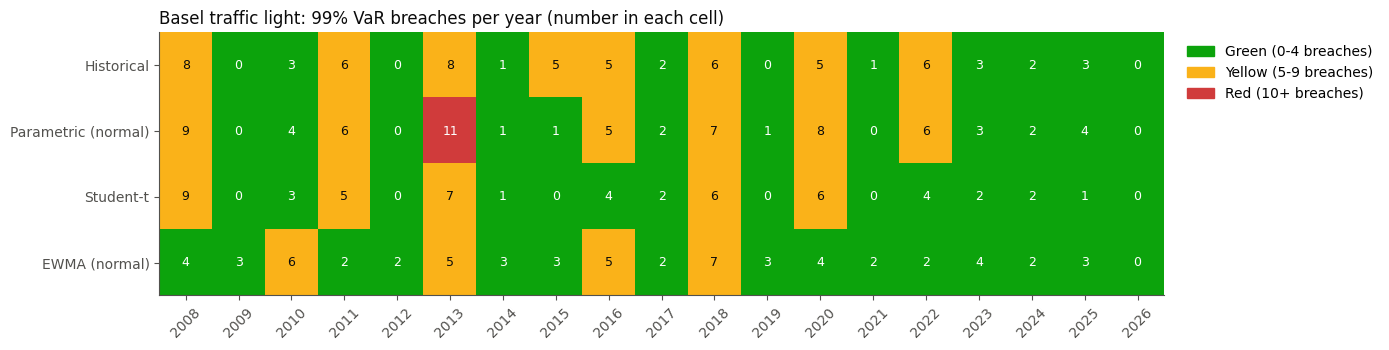

In [104]:

ZONE_COLORS = {"Green": "#0ca30c", "Yellow": "#fab219", "Red": "#d03b3b"}
zone_num = zones.replace({"Green": 0, "Yellow": 1, "Red": 2}).astype(int)

fig, ax = plt.subplots(figsize=(14, 3.6))
ax.imshow(zone_num.T.values, cmap=ListedColormap(list(ZONE_COLORS.values())), vmin=0, vmax=2, aspect="auto")
for i, method in enumerate(yearly.columns):                        # write the breach count in each cell
    for j, year in enumerate(yearly.index):
        zone = zones.loc[year, method]
        ax.text(j, i, int(yearly.loc[year, method]), ha="center", va="center", fontsize=9,
                color=INK if zone == "Yellow" else "white")
ax.set_xticks(range(len(yearly.index)))
ax.set_xticklabels(yearly.index, rotation=45)
ax.set_yticks(range(len(yearly.columns)))
ax.set_yticklabels(yearly.columns)
ax.grid(False)
ax.set_title("Basel traffic light: 99% VaR breaches per year (number in each cell)",
             loc="left", color=INK, fontsize=12)
ax.legend(handles=[Patch(color=c, label=f"{z} ({'0-4' if z == 'Green' else '5-9' if z == 'Yellow' else '10+'} breaches)")
                   for z, c in ZONE_COLORS.items()],
          frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("/content/images/basel_traffic_light.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**EWMA spends the most years in the green zone (15 of 19); parametric VaR is the only method to reach the red zone (2013)**
- Years in each zone: EWMA 15 green / 4 yellow / 0 red; Student-t 14 / 5 / 0; parametric 12 / 6 / 1; historical 11 / 8 / 0.
- **2013 and 2018** were difficult for every method: all four were in the yellow zone in both years, and parametric VaR reached the **red zone in 2013 with 11 breaches**.
- **2008** (189 days, partial year): the three window-based methods had 8–9 breaches (yellow), while EWMA had 4 (green), as it raised its VaR fastest when the crisis started.
- **2009**: historical, parametric and Student-t had **0 breaches**, because their VaR was still inflated by the 2008 crisis days in the window. EWMA had 3.
- The most recent years (2023–2026) are green for all methods; 2026 (220 days so far) has no breaches at all.
- Note: 2008 (189 days), 2025 (201 days, due to bond data gaps) and 2026 (220 days) are partial years.

## 3.4 VaR vs actual P&L over time

The first chart shows each method's 99% VaR forecast (drawn as a loss, below zero) against the daily P&L from 2008 to 2026. **Red dots** mark breaches: days the loss went below the VaR line. The dashed line is the MXN 1.5M risk limit.

The second chart zooms in on the start of the **2008 GFC** and **2020 COVID** crises to show **how quickly each model raised its VaR** when markets turned. A model that reacts slowly lets several large losses through before catching up.

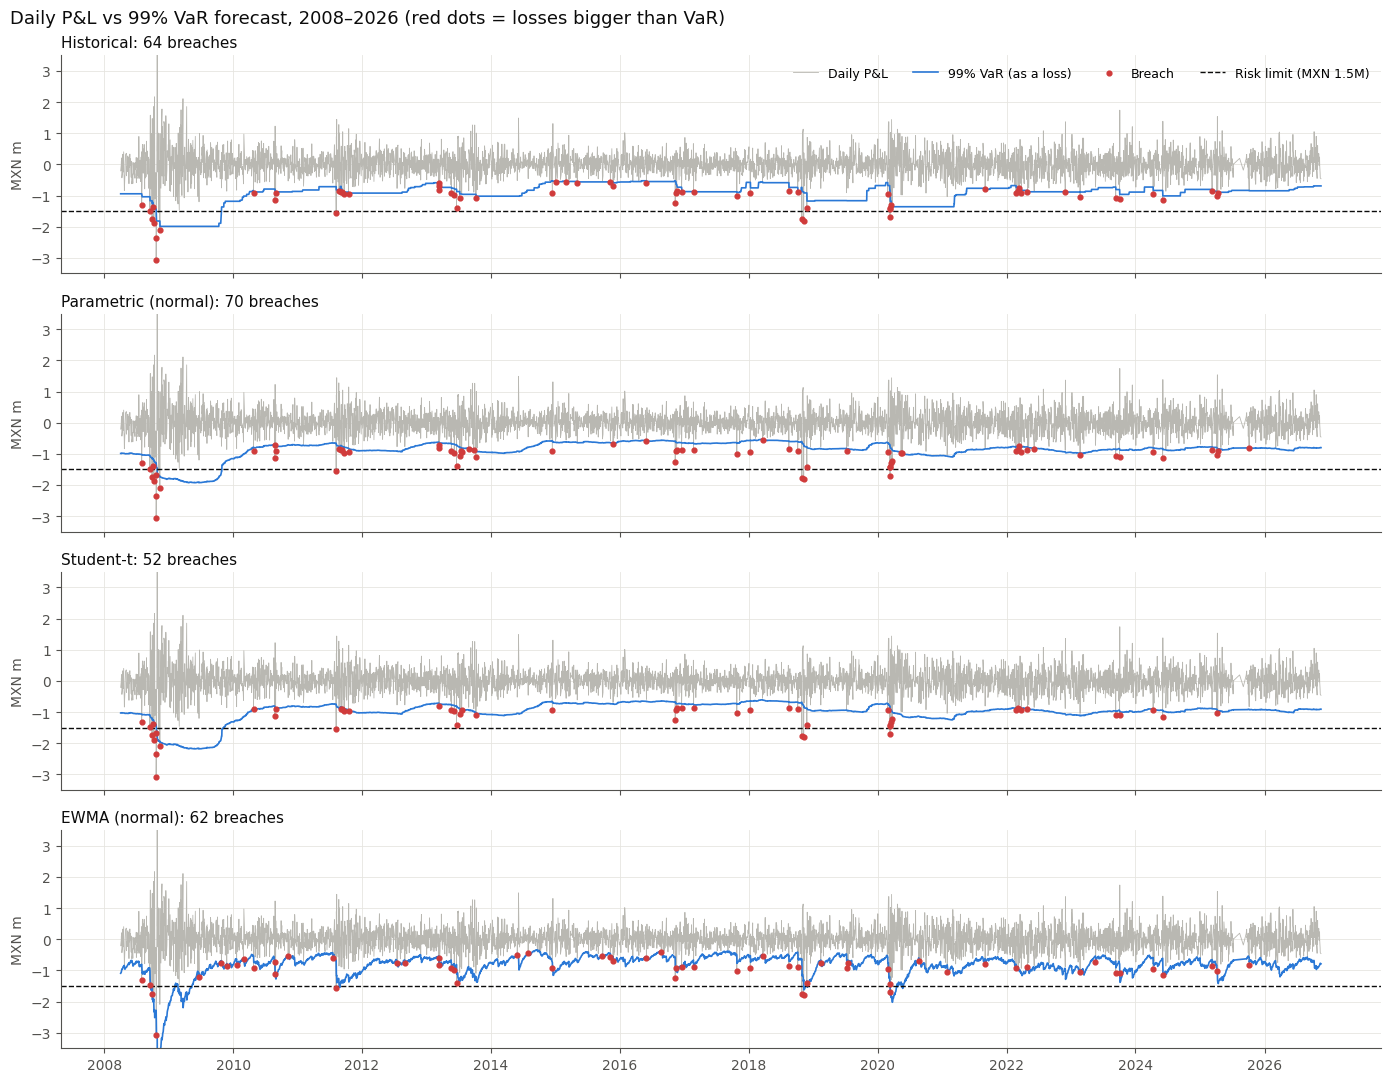

In [106]:
fig, axes = plt.subplots(len(METHODS), 1, figsize=(14, 11), sharex=True, sharey=True)
pnl_bt_m = total.loc[var_fc.index] / 1e6
for ax, method in zip(axes, METHODS):
    v = var_fc[(method, 0.99)] / 1e6
    b = breaches[(method, 0.99)]
    ax.plot(pnl_bt_m.index, pnl_bt_m, color="#b9b8b2", linewidth=0.6, label="Daily P&L")
    ax.plot(v.index, -v, color="#2a78d6", linewidth=1.2, label="99% VaR (as a loss)")
    ax.scatter(pnl_bt_m.index[b], pnl_bt_m[b], color=ZONE_COLORS["Red"], s=12, zorder=3, label="Breach")
    ax.axhline(-RISK_LIMIT / 1e6, color=INK, linestyle="--", linewidth=1, label="Risk limit (MXN 1.5M)")
    ax.set_title(f"{method}: {int(b.sum())} breaches", loc="left", color=INK, fontsize=11)
    ax.set_ylabel("MXN m")
axes[0].legend(frameon=False, ncol=4, loc="upper right", fontsize=9)
axes[0].set_ylim(-3.5, 3.5)
fig.suptitle("Daily P&L vs 99% VaR forecast, 2008–2026 (red dots = losses bigger than VaR)",
             x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.show()

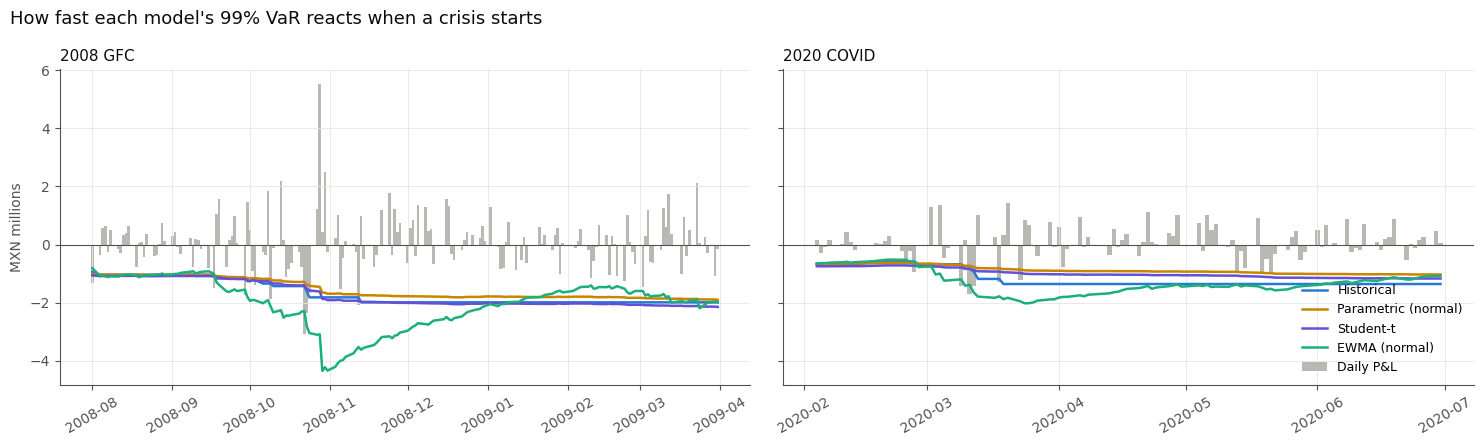

In [107]:
METHOD_COLORS = {"Historical": "#2a78d6", "Parametric (normal)": "#c98500",
                 "Student-t": "#6250d6", "EWMA (normal)": "#1baf7a"}
zoom_periods = {"2008 GFC": ("2008-08-01", "2009-03-31"), "2020 COVID": ("2020-02-01", "2020-06-30")}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (name, (start, end)) in zip(axes, zoom_periods.items()):
    p = pnl_bt_m.loc[start:end]
    ax.bar(p.index, p, color="#b9b8b2", width=1.0, label="Daily P&L")
    for method in METHODS:
        v = var_fc[(method, 0.99)].loc[start:end] / 1e6
        ax.plot(v.index, -v, color=METHOD_COLORS[method], linewidth=1.8, label=method)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_title(name, loc="left", color=INK, fontsize=11)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("MXN millions")
axes[1].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("How fast each model's 99% VaR reacts when a crisis starts", x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.savefig("/content/images/var_crisis_reaction.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**EWMA reacts to a crisis within days, while the window-based methods react late and then stay too high long after the crisis ends**
- **Start of the 2008 crisis:** all methods had a 99% VaR of about MXN 1M in early September 2008. EWMA rose to about MXN 2.4M by mid-October, while the other three stayed around MXN 1.0–1.4M. On 22 Oct 2008 (loss MXN 3.07M) every method was breached. EWMA then peaked at MXN 4.35M on 29 Oct 2008.
- **After the 2008 crisis:** historical, parametric and Student-t VaR stayed close to MXN 2M until late 2009, because the crisis days remained in their 250-day window ("ghost effect"). EWMA had already fallen back to about MXN 2M by January 2009 and continued to decline.
- **COVID (March 2020):** EWMA rose to about MXN 2M within days of the sell-off, while parametric and Student-t VaR barely moved (about MXN 0.8–1.0M). Historical VaR stepped up to about MXN 1.35M only after the 11 Mar 2020 loss entered its window.
- **The downside of EWMA:** in calm periods (e.g., 2014–2017) its VaR falls quickly to about MXN 0.5M, so ordinary bad days breach it more often. Its breaches are spread across many years rather than concentrated in crises.
- Historical VaR moves in steps: it only changes when an extreme day enters or leaves the window, so it can stay unchanged for months.

## 3.5 Risk limit check

This step checks the **MXN 1.5M daily 99% VaR limit** against history:
- **Average and maximum VaR:** a higher average VaR means more capital tied up; the maximum shows how high each model went in a crisis.
- **Days above the limit:** how often each model would have told the risk team to cut positions, and in which years.
- **Actual losses above MXN 1.5M:** how often the portfolio really lost more than the limit in a single day.

In [108]:
rows = []
for method in METHODS:
    v = var_fc[(method, 0.99)]
    over = v > RISK_LIMIT
    rows.append({"method": method,
                 "avg_99_VaR_MXN_m": v.mean() / 1e6,
                 "max_99_VaR_MXN_m": v.max() / 1e6,
                 "date_of_max": v.idxmax().date(),
                 "days_VaR_above_limit": int(over.sum()),
                 "share_of_days_above_limit_%": over.mean() * 100})
limit_table = pd.DataFrame(rows).set_index("method")
display(limit_table.round(3))

over_by_year = pd.DataFrame({m: (var_fc[(m, 0.99)] > RISK_LIMIT) for m in METHODS})
over_by_year = over_by_year.groupby(over_by_year.index.year).sum()
over_by_year = over_by_year[over_by_year.sum(axis=1) > 0]
print("Days with 99% VaR above the MXN 1.5M limit, by year (years with none are hidden):")
display(over_by_year)

actual_over = loss_bt > RISK_LIMIT
print(f"Days with an actual loss above MXN 1.5M: {int(actual_over.sum())}")
loss_bt[actual_over].div(1e6).round(2).rename("loss_MXN_m").to_frame()

,avg_99_VaR_MXN_m,max_99_VaR_MXN_m,date_of_max,days_VaR_above_limit,share_of_days_above_limit_%
method,,,,,
Historical,0.921,1.990,2008-11-13,252,5.478
Parametric (normal),0.858,1.927,2009-06-23,250,5.435
Student-t,0.970,2.180,2009-06-23,260,5.652
EWMA (normal),0.826,4.349,2008-10-29,191,4.152


Days with 99% VaR above the MXN 1.5M limit, by year (years with none are hidden):


,Historical,Parametric (normal),Student-t,EWMA (normal)
date,,,,
2008,47,43,47,70
2009,205,207,213,79
2011,0,0,0,2
2018,0,0,0,11
2020,0,0,0,29


Days with an actual loss above MXN 1.5M: 11


,loss_MXN_m
date,
2008-09-29,1.75
2008-10-09,1.88
2008-10-22,3.07
2008-10-23,2.35
2008-10-24,1.68
2008-11-05,1.55
2008-11-12,2.09
2011-08-08,1.55
2018-10-29,1.76


**Finding:**

**The window-based models would have kept VaR above the MXN 1.5M limit for most of 2009, after the crisis had ended, while EWMA flagged the 2018 and 2020 stress periods that the other models missed**
- Average 99% VaR over 2008–2026: EWMA MXN 0.826M (lowest), parametric MXN 0.858M, historical MXN 0.921M, Student-t MXN 0.970M (highest).
- Maximum 99% VaR: EWMA MXN 4.349M (29 Oct 2008), Student-t MXN 2.180M and parametric MXN 1.927M (both 23 Jun 2009), historical MXN 1.990M (13 Nov 2008). The window-based models peaked eight months after the crisis peak.
- Days with VaR above the MXN 1.5M limit: Student-t 260 (5.65%), historical 252 (5.48%), parametric 250 (5.44%), EWMA 191 (4.15%).
- **Timing matters more than the totals:** in 2008, EWMA was above the limit on 70 days vs 43–47 for the others (an earlier warning). In 2009, the window-based models were above the limit on 205–213 days vs 79 for EWMA. They would have forced the risk team to keep cutting positions long after markets had recovered.
- Only EWMA rose above the limit in 2011 (2 days), 2018 (11 days) and 2020 (29 days), the periods with the largest losses outside 2008.
- The portfolio lost more than MXN 1.5M in a single day on **11 days**: 7 in Sep–Nov 2008 (largest: MXN 3.07M on 22 Oct 2008), plus 8 Aug 2011 (MXN 1.55M), 29 Oct 2018 (MXN 1.76M), 8 Nov 2018 (MXN 1.81M) and 11 Mar 2020 (MXN 1.70M).

## 3.6 Method scorecard

All the backtest results for 99% VaR in one table, to choose the most suitable method. A good method should:
1. have a breach count close to the expected number (Kupiec p ≥ 0.05),
2. not let breaches cluster (Christoffersen p ≥ 0.05),
3. spend few years in the yellow or red Basel zones,
4. without an unnecessarily high average VaR (which would tie up capital).

In [109]:
score = bt_results[bt_results["confidence"] == "99%"].set_index("method")[
    ["expected_breaches", "actual_breaches", "kupiec_p", "back_to_back_breaches", "christoffersen_p", "result"]]
score["years_red"]            = zone_count.loc["Red"]
score["years_yellow"]         = zone_count.loc["Yellow"]
score["avg_99_VaR_MXN_m"]     = limit_table["avg_99_VaR_MXN_m"]
score["days_VaR_above_limit"] = limit_table["days_VaR_above_limit"]
score.round(3)

,expected_breaches,actual_breaches,kupiec_p,back_to_back_breaches,christoffersen_p,result,years_red,years_yellow,avg_99_VaR_MXN_m,days_VaR_above_limit
method,,,,,,,,,,
Historical,46.0,64,0.012,2,0.304,FAIL,0,8,0.921,252
Parametric (normal),46.0,70,0.001,3,0.117,FAIL,1,6,0.858,250
Student-t,46.0,52,0.384,3,0.023,FAIL,0,5,0.970,260
EWMA (normal),46.0,62,0.024,0,0.193,FAIL,0,4,0.826,191


**Finding:**

**No method passes at 99%; EWMA offers the best overall balance, and Student-t is the most accurate on breach count**
- **EWMA (normal):** 62 breaches (Kupiec p = 0.024), but 0 back-to-back breaches, the fewest yellow years (4), the lowest average VaR (MXN 0.826M) and the fewest days above the limit (191). It is the most responsive and the cheapest in capital, but slightly too low overall.
- **Student-t:** 52 breaches, the closest to the 46 expected (Kupiec p = 0.384), 5 yellow years, but breaches cluster (Christoffersen p = 0.023) and it has the highest average VaR (MXN 0.970M).
- **Historical:** 64 breaches (Kupiec p = 0.012), 8 yellow years, the most of any method, and slow to adjust.
- **Parametric (normal):** the weakest: 70 breaches (Kupiec p = 0.001) and the only red year (2013).
- The two best methods fail for opposite reasons: Student-t has the right tail size but reacts slowly, and EWMA reacts quickly but assumes normal tails. Combining them (EWMA volatility with a Student-t distribution) is the natural next improvement.

**Summary - Section 3: Backtesting**

**Key results**
- Over 4,600 days (Apr 2008 – Nov 2026), **all four methods pass at 95%**, but **none passes both tests at 99%**, where 46 breaches were expected: parametric 70, historical 64, EWMA 62, Student-t 52.
- **Student-t** is the only method with an acceptable number of 99% breaches (Kupiec p = 0.384), but its breaches cluster (Christoffersen p = 0.023).
- **EWMA** has no back-to-back breaches, the most green years (15 of 19), the lowest average VaR (MXN 0.826M) and the fewest days above the limit (191), but slightly too many breaches overall (Kupiec p = 0.024).
- **Parametric (normal)** performs worst (70 breaches, Kupiec p = 0.001) and is the only method to reach the Basel red zone (11 breaches in 2013).
- The window-based methods react late to crises and stay high afterwards: they peaked eight months after the 2008 crisis (23 Jun 2009) and kept VaR above the MXN 1.5M limit on 205–213 days in 2009, vs 79 for EWMA.
- The portfolio lost more than the MXN 1.5M limit in a single day on 11 days: 7 in late 2008, plus 8 Aug 2011, 29 Oct and 8 Nov 2018, and 11 Mar 2020.

**Business implications**
1. **A normal-distribution VaR should not be used to set limits or capital for this portfolio:** it was breached 52% more often than expected (70 vs 46) and would have triggered a Basel red-zone capital penalty in 2013.
2. **Model speed matters as much as model accuracy.** Window-based models warn too late when a crisis starts and keep limits too tight after it ends, which would force the desk to cut positions after markets had already recovered.
3. **EWMA is the best early-warning tool:** it was the only model to signal the 2018 and 2020 stress periods by rising above the limit.
4. **The MXN 1.5M limit is broadly appropriate in normal markets**, with VaR averaging MXN 0.83–0.97M, but single-day losses above it do happen (11 times in 18 years), so the limit needs to be supported by stress testing.
5. At 95%, all methods are reliable, so day-to-day risk reporting at 95% is robust whichever method is used; the model choice matters for the 99% tail.

**Recommendations for next steps**
- *Insight:* Student-t gets the tail size right but reacts slowly; EWMA reacts fast but assumes normal tails. → *Recommendation:* adopt a combined **EWMA-volatility Student-t VaR** for limits and capital, and backtest it with the same tests.
- *Insight:* until a combined model is in place, EWMA has the best overall balance (fewest yellow years, no clustering, lowest capital). → *Recommendation:* use EWMA as the primary daily VaR, with Student-t VaR as a conservative cross-check.
- *Insight:* every method was breached on the largest crisis days (e.g., 22 Oct 2008, MXN 3.07M). → *Recommendation:* in Section 4, stress test today's portfolio against the 2008, 2016, 2018 and 2020 episodes and a Banxico +300 bp scenario, to measure losses that VaR does not capture.

**Limitations**
- The Monte Carlo methods are represented by their formula equivalents; full simulation results could differ slightly.
- Positions are held at today's fixed weights throughout 2008–2026, so the backtest measures the models, not a real trading history.
- 2008, 2025 and 2026 are partial years, and bond data gaps in Jul–Sep 2025 reduce the number of test days in 2025.
- The Basel traffic light is applied to calendar years rather than a rolling 250-day period, as regulators do.

# Section 4 - Stress Testing: What Happens in a Crisis?

**Objective:** Measure how much **today's** portfolio would lose if a major crisis happened now, and compare those losses with what the VaR models say.

**Why stress testing is needed:** VaR describes a "normal bad day" based on the past year. Sections 2 and 3 showed that VaR misses the worst crisis days: every method was breached on 22 Oct 2008. Stress testing asks a different question: *"If a disaster happens, how much could we lose, and could we survive it?"*

**Two types of stress test**
- **Historical:** replay real crises (2008, 2016, 2018, 2020) on today's portfolio.
- **Hypothetical:** design plausible scenarios that haven't happened yet (e.g., Banxico raising rates by 3 percentage points).

A **reverse stress test** then asks the opposite question: *"How big would a shock need to be to cause a loss we can't accept?"*

## 4.1 Setup

This step sets up the tools used in every stress test:

- **Today's portfolio:** MXN 40M bonds, MXN 30M IPC stocks, MXN 30M US dollars, with today's bond yield.
- **Exact bond repricing:** for large yield moves (hundreds of basis points), the bond is fully revalued with the price formula instead of the duration shortcut. Section 1.6 showed the shortcut becomes less accurate for big shocks.
- **Crisis windows:** the four stress periods identified in Sections 1–3 (2008 GFC, 2016 US election, 2018 Mexico sell-off, 2020 COVID).
- **Benchmarks:** today's risk numbers from Section 2, to compare against the stress losses. The most conservative estimates are used: Student-t VaR and ES (1-day and 10-day), the full-history 10-day ES and the MXN 1.5M daily limit.

In [110]:

y_today = market["mbono10y"].iloc[-1]                 # today's 10-year yield (%)
price_today = bond_price(y_today, y_today)            # today's bond price (par bond = 100)

def stress_pnl(ipc_ret, usdmxn_ret, dy_bp):
    """P&L (MXN) of TODAY's portfolio for given market moves.
    ipc_ret / usdmxn_ret = % change as decimals (-0.15 = -15%), dy_bp = yield change in basis points.
    The bond is fully repriced (exact formula), which is more accurate than duration for big moves."""
    ipc_ret, usdmxn_ret, dy_bp = (np.atleast_1d(np.asarray(x, dtype=float)) for x in (ipc_ret, usdmxn_ret, dy_bp))
    bond_ret = np.array([bond_price(y_today, y_today + d / 100) / price_today - 1 for d in dy_bp])
    out = pd.DataFrame({
        "ipc_move_%":      ipc_ret * 100,
        "usdmxn_move_%":   usdmxn_ret * 100,
        "yield_change_bp": dy_bp,
        "bond": POSITIONS["bond"] * bond_ret,
        "ipc":  POSITIONS["ipc"]  * ipc_ret,
        "usd":  POSITIONS["usd"]  * usdmxn_ret,
    })
    out["total"] = out[["bond", "ipc", "usd"]].sum(axis=1)
    return out

# Historical stress periods (from Sections 1 and 3)
SCENARIO_WINDOWS = {
    "2008 GFC":             ("2008-09-01", "2009-03-31"),
    "2016 US election":     ("2016-11-01", "2017-01-31"),
    "2018 Mexico sell-off": ("2018-10-01", "2018-12-31"),
    "2020 COVID":           ("2020-02-15", "2020-04-30"),
}

# What today's risk models say (from Section 2), to compare the stress losses against
benchmarks = pd.Series({
    "1-day 99% VaR (Student-t)":        var_summary.loc["Monte Carlo (Student-t)", "VaR_99_1d"],
    "1-day 99% ES (Student-t)":         var_summary.loc["Monte Carlo (Student-t)", "ES_99_1d"],
    "Daily risk limit":                 RISK_LIMIT / 1e6,
    "10-day 99% VaR (Student-t, √10)":  var_summary.loc["Monte Carlo (Student-t)", "VaR_99_10d_sqrt10"],
    "10-day 99% ES (full history)":     tenday_table.query("window == 'Full history' and confidence == '99%'")
                                                    ["actual_10d_ES_MXN_m"].iloc[0],
}, name="MXN_m")

print(f"Today's yield: {y_today:.2f}%  |  positions: bond MXN 40M, IPC MXN 30M, USD MXN 30M")
benchmarks.round(3).to_frame()

Today's yield: 9.30%  |  positions: bond MXN 40M, IPC MXN 30M, USD MXN 30M


,MXN_m
1-day 99% VaR (Student-t),0.940
1-day 99% ES (Student-t),1.320
Daily risk limit,1.500
"10-day 99% VaR (Student-t, √10)",2.972
10-day 99% ES (full history),3.781


**Outcome:** Today's portfolio holds MXN 40M in 10-year bonds (yield 9.30%), MXN 30M in IPC stocks and MXN 30M in US dollars. The stress losses are compared with today's most conservative risk numbers from Section 2: 1-day 99% VaR of MXN 0.94M and ES of MXN 1.32M, 10-day 99% VaR of MXN 2.97M and 10-day ES of MXN 3.78M, and the daily risk limit of MXN 1.5M.

## 4.2 Historical stress tests

Each crisis is replayed on **today's** portfolio: "if the same market moves happened tomorrow, what would we lose?" Three time frames are measured for each crisis:

- **Worst 1 day:** the single worst day of the crisis.
- **Worst 10 days:** the worst two-week stretch (matches the regulatory 10-day horizon).
- **Whole episode (worst point):** the biggest total loss from the start of the crisis, assuming the portfolio is **not traded**, i.e., nobody cuts positions.

The table also shows the market moves behind each loss (IPC %, USD/MXN %, yield change in bp), so each result can be explained.

**Charts:**
1. Each crisis broken down **by leg**, to see which positions lose and whether the USD position offsets them.
2. How the loss **builds up day by day** during each crisis.

In [111]:
# Map each market date to its Mexican business-day number, to find dates exactly 10 business days apart
mkt_pos = pd.Series(fx_calendar.get_indexer(market.index), index=market.index)
date_at_pos = pd.Series(market.index, index=mkt_pos.values)

def moves_between(start_dates, end_dates):
    """Market moves between pairs of dates: IPC % change, USD/MXN % change, yield change (bp)."""
    a, b = market.loc[start_dates], market.loc[end_dates]
    return (b["ipc"].values / a["ipc"].values - 1,
            b["usdmxn"].values / a["usdmxn"].values - 1,
            (b["mbono10y"].values - a["mbono10y"].values) * 100)

rows, episode_paths = [], {}
for name, (start, end) in SCENARIO_WINDOWS.items():
    in_window = market.loc[start:end].index

    # (a) Worst single day: each clean daily move in the window applied to today's portfolio
    f = factors.loc[start:end]
    p1 = stress_pnl(f["ipc_ret"], f["usdmxn_ret"], f["bond_dy_bp"]); p1.index = f.index

    # (b) Worst 10 days: moves over every 10-business-day period ending in the window
    ends = [t for t in in_window if (mkt_pos[t] - HORIZON) in date_at_pos.index]
    starts = [date_at_pos[mkt_pos[t] - HORIZON] for t in ends]
    p10 = stress_pnl(*moves_between(starts, ends)); p10.index = ends

    # (c) Whole episode: cumulative moves from the day before the crisis to each day; take the worst point
    base = market.index[market.index < start][-1]
    pe = stress_pnl(*moves_between([base] * len(in_window), in_window)); pe.index = in_window
    episode_paths[name] = pe["total"]

    for horizon, table in [("Worst 1 day", p1), ("Worst 10 days", p10), ("Whole episode (worst point)", pe)]:
        d = table["total"].idxmin()
        rows.append({"scenario": name, "horizon": horizon, "date": d.date(), **table.loc[d].to_dict()})

hist_stress = pd.DataFrame(rows).set_index(["scenario", "horizon"])
for col in ["bond", "ipc", "usd", "total"]:
    hist_stress[col] = hist_stress[col] / 1e6                       # MXN millions
hist_stress.round(2)

date  ipc_move_%  \
scenario             horizon                                               
2008 GFC             Worst 1 day                  2008-10-22       -7.01   
                     Worst 10 days                2008-10-27      -23.56   
                     Whole episode (worst point)  2008-10-24      -35.42   
2016 US election     Worst 1 day                  2016-11-10       -4.57   
                     Worst 10 days                2016-11-24       -4.48   
                     Whole episode (worst point)  2016-11-18       -7.59   
2018 Mexico sell-off Worst 1 day                  2018-11-08       -5.81   
                     Worst 10 days                2018-11-20      -10.72   
                     Whole episode (worst point)  2018-11-26      -20.36   
2020 COVID           Worst 1 day                  2020-03-11       -2.24   
                     Worst 10 days                2020-03-19      -19.03   
                     Whole episode (worst point)  2020-03-12      -18.58   

                                                  usdmxn_move_%  \
scenario             horizon                                      
2008 GFC             Worst 1 day                           3.32   
                     Worst 10 days                         7.55   
                     Whole episode (worst point)          30.29   
2016 US election     Worst 1 day                           2.79   
                     Worst 10 days                         3.92   
                     Whole episode (worst point)           8.10   
2018 Mexico sell-off Worst 1 day                           1.11   
                     Worst 10 days                         2.25   
                     Whole episode (worst point)           9.65   
2020 COVID           Worst 1 day                           0.89   
                     Worst 10 days                        23.31   
                     Whole episode (worst point)          19.28   

                                                  yield_change_bp  bond  \
scenario             horizon                                              
2008 GFC             Worst 1 day                             81.0 -2.01   
                     Worst 10 days                          151.0 -3.64   
                     Whole episode (worst point)            247.0 -5.72   
2016 US election     Worst 1 day                             25.2 -0.64   
                     Worst 10 days                           88.2 -2.18   
                     Whole episode (worst point)            108.0 -2.65   
2018 Mexico sell-off Worst 1 day                             15.0 -0.38   
                     Worst 10 days                           56.0 -1.40   
                     Whole episode (worst point)            129.0 -3.14   
2020 COVID           Worst 1 day                             46.0 -1.16   
                     Worst 10 days                          178.0 -4.24   
                     Whole episode (worst point)            115.0 -2.81   

                                                    ipc   usd  total  
scenario             horizon                                          
2008 GFC             Worst 1 day                  -2.10  1.00  -3.12  
                     Worst 10 days                -7.07  2.26  -8.44  
                     Whole episode (worst point) -10.63  9.09  -7.26  
2016 US election     Worst 1 day                  -1.37  0.84  -1.17  
                     Worst 10 days                -1.35  1.17  -2.35  
                     Whole episode (worst point)  -2.28  2.43  -2.50  
2018 Mexico sell-off Worst 1 day                  -1.74  0.33  -1.79  
                     Worst 10 days                -3.22  0.67  -3.95  
                     Whole episode (worst point)  -6.11  2.90  -6.35  
2020 COVID           Worst 1 day                  -0.67  0.27  -1.56  
                     Worst 10 days                -5.71  6.99  -2.96  
                     Whole episode (worst point)  -5.58  5.78  -2.60

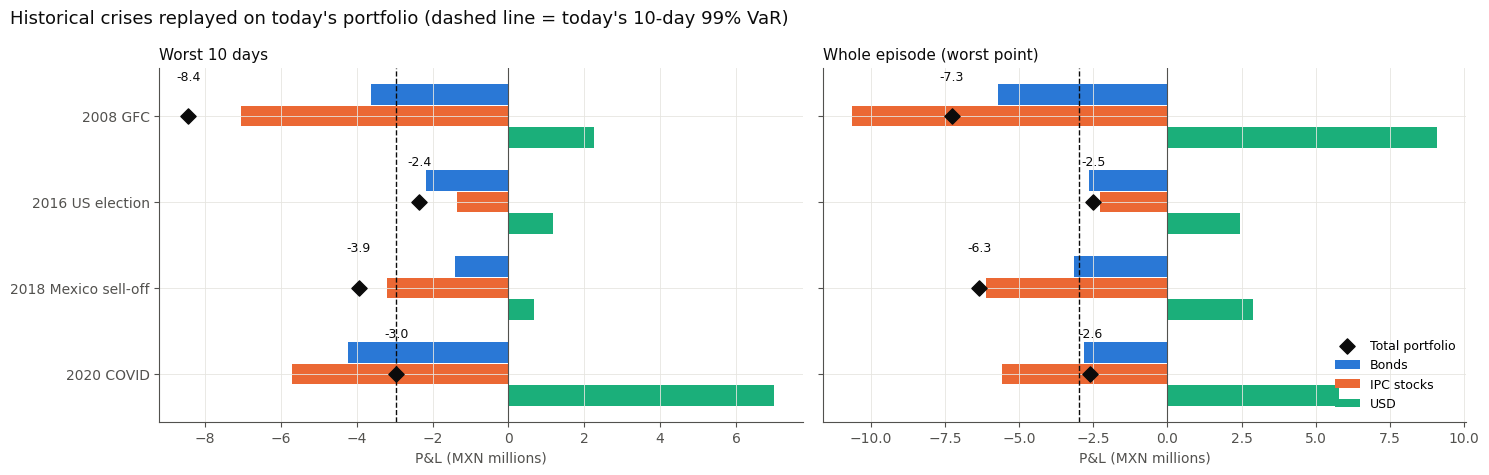

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
scen = list(SCENARIO_WINDOWS)
yy = np.arange(len(scen))
for ax, horizon in zip(axes, ["Worst 10 days", "Whole episode (worst point)"]):
    d = hist_stress.xs(horizon, level="horizon").loc[scen]
    for k, leg in enumerate(legs):
        ax.barh(yy + (k - 1) * 0.25, d[leg], height=0.24, color=COLORS[leg],
                label={"bond": "Bonds", "ipc": "IPC stocks", "usd": "USD"}[leg])
    ax.scatter(d["total"], yy, marker="D", s=60, color=INK, zorder=3, label="Total portfolio")
    for i, v in enumerate(d["total"]):
        ax.text(v, i - 0.42, f"{v:.1f}", ha="center", fontsize=9, color=INK)
    ax.axvline(-benchmarks["10-day 99% VaR (Student-t, √10)"], color=INK, linestyle="--", linewidth=1)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_title(horizon, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("P&L (MXN millions)")
axes[0].set_yticks(yy); axes[0].set_yticklabels(scen); axes[0].invert_yaxis()
axes[1].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("Historical crises replayed on today's portfolio (dashed line = today's 10-day 99% VaR)",
             x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.savefig("/content/images/historical_stress_by_leg.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

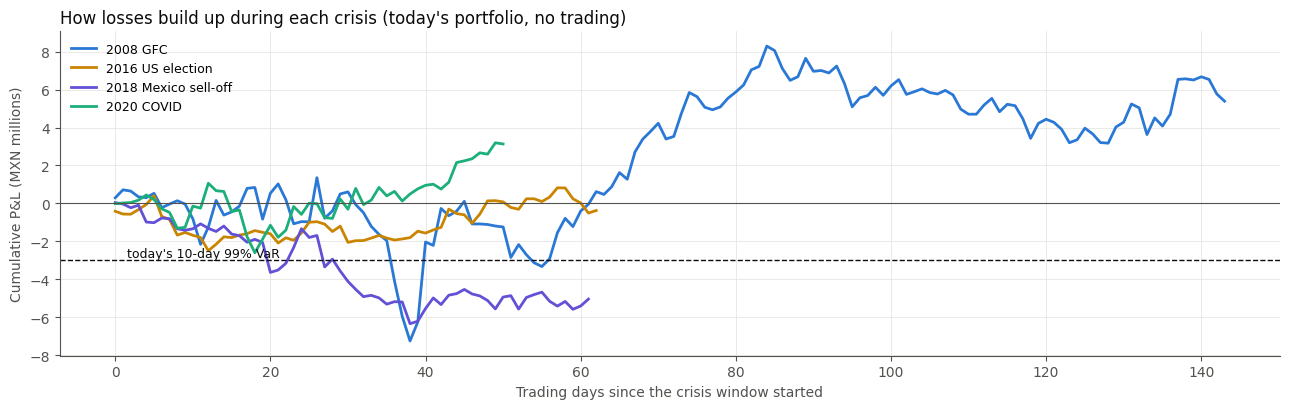

In [113]:
fig, ax = plt.subplots(figsize=(13, 4.2))
path_colors = {"2008 GFC": "#2a78d6", "2016 US election": "#c98500",
               "2018 Mexico sell-off": "#6250d6", "2020 COVID": "#1baf7a"}
for name, path in episode_paths.items():
    ax.plot(np.arange(len(path)), path / 1e6, color=path_colors[name], linewidth=2, label=name)
ax.axhline(-benchmarks["10-day 99% VaR (Student-t, √10)"], color=INK, linestyle="--", linewidth=1)
ax.text(1, -benchmarks["10-day 99% VaR (Student-t, √10)"], " today's 10-day 99% VaR",
        fontsize=9, color=INK, va="bottom")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("Trading days since the crisis window started")
ax.set_ylabel("Cumulative P&L (MXN millions)")
ax.set_title("How losses build up during each crisis (today's portfolio, no trading)",
             loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Finding:**

**A repeat of 2008 would cost today's portfolio up to MXN 8.4M in two weeks, nearly three times today's 10-day VaR, and the 2018 domestic sell-off is the second most damaging crisis**
- **2008 GFC:** the worst 10 days (to 27 Oct 2008: IPC −23.6%, yields +151 bp) would cost **MXN 8.44M**. The worst single day (22 Oct 2008) would cost MXN 3.12M. The US dollar position gained MXN 2.26M over those 10 days, but stocks (−MXN 7.07M) and bonds (−MXN 3.64M) lost far more.
- **2018 Mexico sell-off:** the loss kept growing for almost two months, reaching **MXN 6.35M** by 26 Nov 2018 (IPC −20.4%, yields +129 bp). The USD position offset only MXN 2.90M, because the peso moved less (+9.7%) in this **local** crisis than in global ones.
- **2020 COVID:** stocks and bonds lost heavily (worst 10 days: IPC −19.0%, yields +178 bp), but the peso also fell sharply (USD/MXN +23.3%), so the USD position gained MXN 6.99M and cut the total loss to **MXN 2.96M**.
- **2016 US election:** the mildest crisis for this portfolio, with a maximum loss of **MXN 2.50M**, as the USD gain (MXN 2.43M) almost matched the stock loss (MXN 2.28M).
- **How losses build up (line chart):** in 2008 the loss reached about MXN 7.3M after about 38 trading days, then recovered into a gain of up to about MXN 8M as the peso kept weakening. The 2018 loss reached about MXN 6.3M and had **not recovered** by the end of the window. 2016 and 2020 recovered to around zero or a gain.
- **Key insight:** the USD position protects the portfolio well in **global** crises (2008, 2020), when the peso falls sharply, but much less in a **Mexico-specific** crisis (2018), when stocks and bonds fall without a big peso move.

## 4.3 Hypothetical stress tests

History doesn't repeat exactly, so two "what if" scenarios are tested:

| Scenario | Market moves | Why it's plausible |
|---|---|---|
| **A. Banxico +300 bp, peso sell-off** | Bond yields +300 bp, USD/MXN +20% (peso weakens), IPC −15% | A sharp rate hike to defend the peso during a currency crisis. Higher rates also hurt stocks (IPC fall is an assumption based on past sell-offs). |
| **B. Hedge failure** | Bond yields +200 bp, IPC −20%, USD/MXN −5% (peso **strengthens**) | Bonds and stocks fall together while the peso rises, so the USD position **loses** instead of protecting. This happened on 9 Oct 2008 (Section 1), and Section 2 found the USD position currently does not hedge the bond position. |

Scenario A tests the classic emerging-market crisis; scenario B tests what happens if the natural hedge stops working.

In [114]:
HYPOTHETICAL = {
    "Banxico +300 bp, USD/MXN +20%, IPC −15%":       {"ipc_ret": -0.15, "usdmxn_ret":  0.20, "dy_bp": 300},
    "Hedge failure: +200 bp, IPC −20%, USD/MXN −5%": {"ipc_ret": -0.20, "usdmxn_ret": -0.05, "dy_bp": 200},
}

hypo = pd.concat([stress_pnl(s["ipc_ret"], s["usdmxn_ret"], s["dy_bp"]).assign(scenario=name)
                  for name, s in HYPOTHETICAL.items()]).set_index("scenario")
for col in ["bond", "ipc", "usd", "total"]:
    hypo[col] = hypo[col] / 1e6                                     # MXN millions
hypo.round(2)

,ipc_move_%,usdmxn_move_%,yield_change_bp,bond,ipc,usd,total
scenario,,,,,,,
"Banxico +300 bp, USD/MXN +20%, IPC −15%",-15.0,20.0,300.0,-6.80,-4.5,6.0,-5.30
"Hedge failure: +200 bp, IPC −20%, USD/MXN −5%",-20.0,-5.0,200.0,-4.72,-6.0,-1.5,-12.22


**Finding:**

**If the USD hedge fails, a moderate shock costs MXN 12.2M, more than twice the loss from a much larger Banxico rate shock**
- **Scenario A (Banxico +300 bp, USD/MXN +20%, IPC −15%):** loss of **MXN 5.30M**. Bonds lose MXN 6.80M (about 17% of their value) and stocks MXN 4.50M, but the USD position gains MXN 6.00M, offsetting more than half of the loss.
- **Scenario B (hedge failure: +200 bp, IPC −20%, USD/MXN −5%):** loss of **MXN 12.22M (12.2% of the portfolio)**, the worst result in this section. All three positions lose at the same time: bonds MXN 4.72M, stocks MXN 6.00M and USD MXN 1.50M.
- Scenario B uses **smaller** rate and peso moves than scenario A, yet loses more than twice as much. The portfolio's biggest vulnerability is not the size of a shock, but a shock where **the peso does not weaken**.

## 4.4 Stress losses vs VaR

All stress results are ranked and compared with today's risk numbers, to show **how much VaR understates crisis losses**:

- **x_VaR:** the stress loss as a multiple of VaR (2.0 = twice what VaR expects).
- **x_ES:** the same against Expected Shortfall (the average of the worst days).
- **x_daily_limit:** the stress loss as a multiple of the MXN 1.5M daily limit.

To compare like with like, **1-day** stress losses are compared with **1-day** VaR and ES, and longer scenarios with **10-day** VaR and ES.

In [115]:
compare = []
for (name, horizon), r in hist_stress.iterrows():
    compare.append({"scenario": f"{name} – {horizon.lower()}", "type": "Historical",
                    "is_one_day": horizon == "Worst 1 day", "loss_MXN_m": -r["total"]})
for name, r in hypo.iterrows():
    compare.append({"scenario": name, "type": "Hypothetical", "is_one_day": False, "loss_MXN_m": -r["total"]})
compare = pd.DataFrame(compare).set_index("scenario")

compare["%_of_portfolio"] = compare["loss_MXN_m"] * 1e6 / PORTFOLIO_VALUE * 100
# 1-day losses are compared with 1-day measures; longer scenarios with 10-day measures
compare["x_VaR"] = np.where(compare["is_one_day"],
                            compare["loss_MXN_m"] / benchmarks["1-day 99% VaR (Student-t)"],
                            compare["loss_MXN_m"] / benchmarks["10-day 99% VaR (Student-t, √10)"])
compare["x_ES"] = np.where(compare["is_one_day"],
                           compare["loss_MXN_m"] / benchmarks["1-day 99% ES (Student-t)"],
                           compare["loss_MXN_m"] / benchmarks["10-day 99% ES (full history)"])
compare["x_daily_limit"] = compare["loss_MXN_m"] / benchmarks["Daily risk limit"]
compare = compare.sort_values("loss_MXN_m", ascending=False)
compare.drop(columns="is_one_day").round(2)

,type,loss_MXN_m,%_of_portfolio,x_VaR,x_ES,x_daily_limit
scenario,,,,,,
"Hedge failure: +200 bp, IPC −20%, USD/MXN −5%",Hypothetical,12.22,12.22,4.11,3.23,8.15
2008 GFC – worst 10 days,Historical,8.44,8.44,2.84,2.23,5.63
2008 GFC – whole episode (worst point),Historical,7.26,7.26,2.44,1.92,4.84
2018 Mexico sell-off – whole episode (worst point),Historical,6.35,6.35,2.14,1.68,4.23
"Banxico +300 bp, USD/MXN +20%, IPC −15%",Hypothetical,5.30,5.30,1.78,1.40,3.53
2018 Mexico sell-off – worst 10 days,Historical,3.95,3.95,1.33,1.04,2.63
2008 GFC – worst 1 day,Historical,3.12,3.12,3.32,2.36,2.08
2020 COVID – worst 10 days,Historical,2.96,2.96,0.99,0.78,1.97
2020 COVID – whole episode (worst point),Historical,2.60,2.60,0.88,0.69,1.74


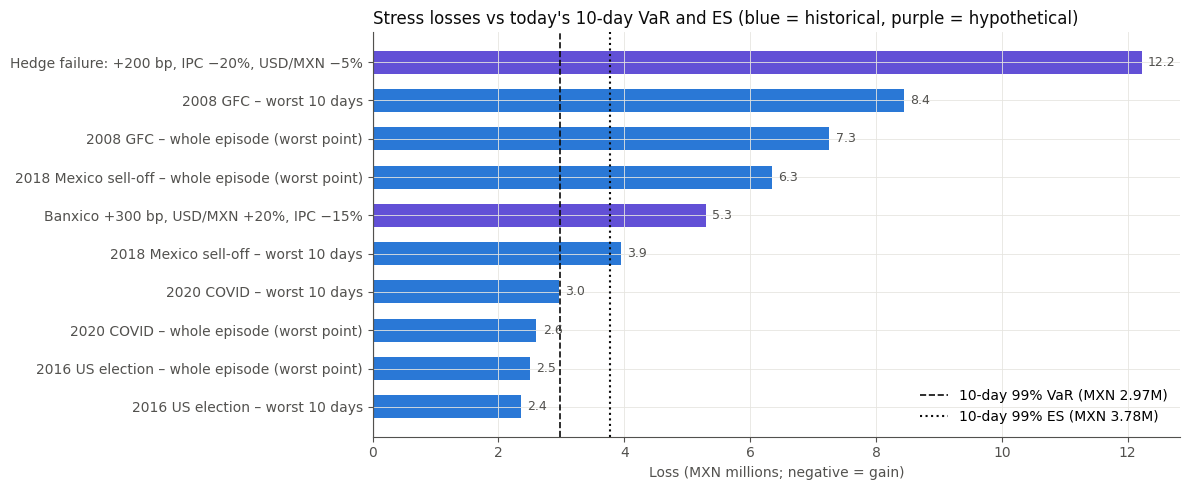

In [116]:
c = compare[~compare["is_one_day"]]                                  # multi-day scenarios only
fig, ax = plt.subplots(figsize=(12, 5))
bar_colors = ["#2a78d6" if t == "Historical" else "#6250d6" for t in c["type"]]
ax.barh(c.index, c["loss_MXN_m"], color=bar_colors, height=0.6)
for i, v in enumerate(c["loss_MXN_m"]):
    ax.text(v + (0.1 if v >= 0 else -0.1), i, f"{v:.1f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=9, color=MUTED)
ax.axvline(benchmarks["10-day 99% VaR (Student-t, √10)"], color=INK, linestyle="--", linewidth=1.2,
           label=f"10-day 99% VaR (MXN {benchmarks['10-day 99% VaR (Student-t, √10)']:.2f}M)")
ax.axvline(benchmarks["10-day 99% ES (full history)"], color=INK, linestyle=":", linewidth=1.5,
           label=f"10-day 99% ES (MXN {benchmarks['10-day 99% ES (full history)']:.2f}M)")
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Loss (MXN millions; negative = gain)")
ax.set_title("Stress losses vs today's 10-day VaR and ES (blue = historical, purple = hypothetical)",
             loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("/content/images/stress_vs_var.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**VaR understates crisis losses by up to four times: 6 of the 10 multi-day scenarios lose more than both today's 10-day VaR and ES**
- **Multi-day scenarios** (vs 10-day VaR of MXN 2.97M and ES of MXN 3.78M): the hedge failure (4.11× VaR), 2008 worst 10 days (2.84×), 2008 whole episode (2.44×), 2018 whole episode (2.14×), Banxico scenario (1.78×) and 2018 worst 10 days (1.33×) all exceed both VaR and ES. COVID's worst 10 days (MXN 2.96M) sits right at VaR (0.99×), and the 2016 results stay below it.
- **Single days** (vs 1-day VaR of MXN 0.94M): all four crises' worst days exceed 1-day VaR, from 1.25× (2016) to **3.32× (2008, MXN 3.12M)**. Three of the four also exceed the MXN 1.5M daily limit; only 2016 stays below it (MXN 1.17M).
- The largest losses range from **5% to 12% of the portfolio** (MXN 5.30M to MXN 12.22M), compared with a daily risk limit of 1.5%.
- VaR and ES are good guides for normal bad days and moderate crises (2016, 2020), but they do not show the size of losses in a severe global crisis (2008), a domestic crisis (2018) or a hedge failure.

## 4.5 Reverse stress test

Instead of asking *"what would this crisis cost?"*, a reverse stress test asks: **"what would it take to lose MXN 10M (10% of the portfolio)?"** This shows how far the portfolio is from a loss the business could not accept.

Two versions are calculated:
1. **One market at a time:** how far bond yields, stocks or the peso would need to move on their own.
2. **Scaled scenarios:** how many times bigger the worst historical crisis and the two hypothetical scenarios would need to be (e.g., "× 1.5" = 50% larger than the scenario).

A multiplier **below 1** means the scenario as designed already causes a loss above MXN 10M.

In [117]:
TARGET_LOSS = 10_000_000          # "what would it take to lose 10% of the portfolio?"

def loss_gap(k, ipc_ret, usdmxn_ret, dy_bp):
    """Loss of today's portfolio when the given moves are multiplied by k, minus the target loss."""
    return -stress_pnl(k * ipc_ret, k * usdmxn_ret, k * dy_bp)["total"].iloc[0] - TARGET_LOSS

rows = []
# (1) One market at a time
rows.append({"shock": "Bond yields only", "move_needed":
             f"+{brentq(lambda d: loss_gap(1, 0, 0, d), 0, 2000):.0f} bp"})
rows.append({"shock": "IPC stocks only", "move_needed":
             f"{-TARGET_LOSS / POSITIONS['ipc'] * 100:.1f}%"})
rows.append({"shock": "Peso only (USD/MXN falls = peso strengthens)", "move_needed":
             f"USD/MXN {-TARGET_LOSS / POSITIONS['usd'] * 100:.1f}%"})

# (2) The worst historical scenario and the two hypothetical ones, scaled until the loss reaches the target
worst_hist = hist_stress[hist_stress.index.get_level_values("horizon") != "Worst 1 day"]["total"].idxmin()
candidates = {f"{worst_hist[0]} – {worst_hist[1].lower()}": hist_stress.loc[worst_hist]}
for name, s in HYPOTHETICAL.items():
    candidates[name] = pd.Series({"ipc_move_%": s["ipc_ret"] * 100, "usdmxn_move_%": s["usdmxn_ret"] * 100,
                                  "yield_change_bp": s["dy_bp"]})
for name, r in candidates.items():
    args = (r["ipc_move_%"] / 100, r["usdmxn_move_%"] / 100, r["yield_change_bp"])
    k_max = 0.99 / abs(args[0]) if args[0] < 0 else 50           # stocks cannot fall more than 100%
    # Solve for the multiplier k only if the scaled scenario can actually reach the target loss
    k = brentq(loss_gap, 0, k_max, args=args) if loss_gap(k_max, *args) > 0 else np.nan
    rows.append({"shock": f"{name} × {k:.2f}" if not np.isnan(k) else f"{name}: never reaches the target",
                 "move_needed": (f"IPC {k*args[0]*100:.1f}%, USD/MXN {k*args[1]*100:+.1f}%, yields {k*args[2]:+.0f} bp"
                                 if not np.isnan(k) else "-")})

reverse = pd.DataFrame(rows).set_index("shock")
print(f"Market moves needed for a loss of MXN {TARGET_LOSS/1e6:.0f}M ({TARGET_LOSS/PORTFOLIO_VALUE:.0%} of the portfolio):")
reverse

Market moves needed for a loss of MXN 10M (10% of the portfolio):


,move_needed
shock,
Bond yields only,+472 bp
IPC stocks only,-33.3%
Peso only (USD/MXN falls = peso strengthens),USD/MXN -33.3%
2008 GFC – worst 10 days × 1.19,"IPC -28.1%, USD/MXN +9.0%, yields +180 bp"
"Banxico +300 bp, USD/MXN +20%, IPC −15% × 2.30","IPC -34.5%, USD/MXN +46.0%, yields +690 bp"
"Hedge failure: +200 bp, IPC −20%, USD/MXN −5% × 0.81","IPC -16.3%, USD/MXN -4.1%, yields +163 bp"


**Finding:**

**A 10% loss (MXN 10M) needs a very large shock while the peso hedge works, but only a moderate shock if it fails**
- **One market at a time:** losing MXN 10M would need bond yields to rise by **472 bp** on their own, stocks to fall **33.3%**, or the peso to strengthen by **33.3%** (USD/MXN −33.3%). Each of these is extreme on its own.
- **2008 crisis:** it would only need to be **19% worse** than its worst 10 days (× 1.19: IPC −28.1%, USD/MXN +9.0%, yields +180 bp). A crisis slightly more severe than 2008 would reach the 10% loss.
- **Banxico scenario:** it would need to be **2.3 times** larger (yields +690 bp, IPC −34.5%, USD/MXN +46.0%), very unlikely, because the peso sell-off keeps protecting the portfolio.
- **Hedge failure:** only **81%** of the scenario is needed (× 0.81: IPC −16.3%, USD/MXN −4.1%, yields +163 bp). These are moves that have happened before (e.g., the 2018 sell-off saw IPC −20.4% and yields +129 bp), so this is the most realistic path to a 10% loss.

**Summary - Section 4: Stress Testing**

**Key results**
- Replaying past crises on today's portfolio, the largest losses are **MXN 8.44M** (2008, worst 10 days) and **MXN 6.35M** (2018 Mexico sell-off). The worst single day is MXN 3.12M (22 Oct 2008), more than twice the MXN 1.5M daily limit.
- The **hedge-failure scenario** (bonds and stocks fall while the peso strengthens) causes the largest loss of all: **MXN 12.22M (12.2% of the portfolio)**, more than twice the Banxico +300 bp scenario (MXN 5.30M).
- Stress losses are up to **4.1 times** today's 10-day VaR. Six of the ten multi-day scenarios exceed both 10-day VaR and ES, and every crisis's worst day exceeds 1-day VaR.
- The USD position cuts losses sharply in **global** crises (e.g., +MXN 6.99M in the worst 10 days of COVID) but protects much less in a **domestic** crisis (2018) and makes losses worse if the peso strengthens.
- A 10% loss would need a crisis 19% worse than 2008's worst two weeks, or just **81%** of the hedge-failure scenario.

**Business implications**
1. **VaR alone is not enough to manage this portfolio.** It describes normal bad days well but understates crisis losses by 1.3 to 4.1 times, so limits and capital also need to be based on stress results.
2. **The portfolio's main weakness is its reliance on the peso hedge.** It is well protected against global shocks, but a Mexico-specific shock or a peso rally would hit stocks and bonds with little or no offset.
3. **Stocks are the largest source of crisis losses** (up to MXN 10.63M in 2008), consistent with the IPC position being the biggest risk contributor in Section 2.
4. **Interest-rate risk is significant in every scenario:** the bond position loses between MXN 0.38M and MXN 6.80M, and a 300 bp rate rise wipes about 17% off its value.
5. Because losses can build up over weeks (2018) without recovering, waiting for markets to bounce back is not a safe strategy; positions need to be cut early when stress builds.

**Recommendations**
- *Insight:* stress losses far exceed VaR. → *Recommendation:* add a **stress loss limit** alongside the daily VaR limit (e.g., maximum loss in the worst historical scenario of 10% of the portfolio), and review it monthly.
- *Insight:* the USD hedge fails in domestic crises and peso rallies. → *Recommendation:* run the hedge-failure scenario as a standard monthly stress test, and consider a direct hedge for the stock and bond positions (e.g., IPC futures or interest-rate swaps) rather than relying on the peso.
- *Insight:* the IPC position drives the largest crisis losses. → *Recommendation:* consider reducing the IPC weight (e.g., from 30% to 20%) and re-running Sections 2–4 to measure the reduction in VaR and stress losses.
- *Insight:* losses build up over several weeks. → *Recommendation:* use the EWMA VaR from Section 3 as an early-warning signal, cutting positions when it rises above the limit.

**Limitations**
- Historical scenarios assume crises repeat with the same market moves; future crises will differ.
- The whole-episode losses assume no trading during the crisis. In practice, positions would be cut, so these are worst-case figures.
- The hypothetical scenario moves (e.g., IPC −15% in scenario A) are assumptions, not forecasts.
- The bond is modelled as a generic 10-year par bond at today's 9.30% yield.

# Section 5 - Conclusions and Recommendations

This section brings the analysis together:
- **5.1** tests whether a **different portfolio mix** would reduce risk, the last open question from Sections 2–4.
- **5.2** collects the **key numbers** from every section in one table.
- **5.3** gives the **overall summary** of Sections 1–5, the **business implications** and the **recommendations**.

## 5.1 Alternative portfolio mixes

Sections 2 and 4 found that the IPC (stock) position drives most of the risk, and that the USD position protects the portfolio in global crises but not in a local one. This step tests **five possible mixes** of the same MXN 100M (bonds / IPC / USD):

| Mix | Idea |
|---|---|
| **Current (40/30/30)** | Today's portfolio, for comparison |
| **Fewer stocks (50/20/30)** | Move 10% from stocks into bonds |
| **Fewer stocks, more USD (40/20/40)** | Move 10% from stocks into US dollars (a bigger hedge) |
| **Bond-heavy (60/20/20)** | Mostly bonds, a smaller stock and USD position |
| **No USD hedge (60/40/0)** | Shows what happens without the US dollar position |

For each mix, two kinds of risk are measured:
- **Normal bad days:** 1-day 99% VaR (last 250 days) and 1-day 99% ES (full history).
- **Crises:** the losses in the key stress scenarios from Section 4, and the worst stress loss overall.

Each leg's stress loss grows or shrinks with the size of the position (e.g., halving the stock position halves the stock loss).

In [118]:
MIXES = {
    "Current (40/30/30)":                {"bond": 0.40, "ipc": 0.30, "usd": 0.30},
    "Fewer stocks (50/20/30)":           {"bond": 0.50, "ipc": 0.20, "usd": 0.30},
    "Fewer stocks, more USD (40/20/40)": {"bond": 0.40, "ipc": 0.20, "usd": 0.40},
    "Bond-heavy (60/20/20)":             {"bond": 0.60, "ipc": 0.20, "usd": 0.20},
    "No USD hedge (60/40/0)":            {"bond": 0.60, "ipc": 0.40, "usd": 0.00},
}

# Daily % returns of each position (from Section 1) and the per-leg stress losses (from Section 4)
daily_returns = pd.DataFrame({"bond": bond_ret, "ipc": factors["ipc_ret"], "usd": factors["usdmxn_ret"]}).dropna()
stress_legs = pd.concat([hist_stress[hist_stress.index.get_level_values("horizon") != "Worst 1 day"][legs],
                         hypo[legs].set_index(pd.MultiIndex.from_product([hypo.index, ["Hypothetical"]]))])

rows = []
for name, w in MIXES.items():
    # Daily P&L history of this mix (MXN), using the same market moves as Section 1
    mix_pnl = sum(daily_returns[leg] * w[leg] * PORTFOLIO_VALUE for leg in legs)
    var_now, _ = hist_var_es(mix_pnl.iloc[-WINDOW:], 0.99)          # current 1-day 99% VaR (last 250 days)
    _, es_full = hist_var_es(mix_pnl, 0.99)                         # 1-day 99% ES over 2007-2026
    # Stress losses: each leg's loss scales with the size of the position (new weight / current weight)
    scale = pd.Series({leg: w[leg] / WEIGHTS[leg] for leg in legs})
    stress_total = (stress_legs * scale).sum(axis=1)                # MXN millions, negative = loss
    rows.append({"mix": name,
                 "VaR_99_1d_MXN_m":          var_now / 1e6,
                 "ES_99_1d_full_hist_MXN_m": es_full / 1e6,
                 "2008_worst_10d_MXN_m":     -stress_total.loc[("2008 GFC", "Worst 10 days")],
                 "2018_episode_MXN_m":       -stress_total.loc[("2018 Mexico sell-off", "Whole episode (worst point)")],
                 "Banxico_+300bp_MXN_m":     -stress_total.iloc[-2],
                 "Hedge_failure_MXN_m":      -stress_total.iloc[-1],
                 "Worst_stress_MXN_m":       -stress_total.min()})
mix_table = pd.DataFrame(rows).set_index("mix")
mix_table.round(2)

,VaR_99_1d_MXN_m,ES_99_1d_full_hist_MXN_m,2008_worst_10d_MXN_m,2018_episode_MXN_m,Banxico_+300bp_MXN_m,Hedge_failure_MXN_m,Worst_stress_MXN_m
mix,,,,,,,
Current (40/30/30),0.69,1.33,8.44,6.35,5.3,12.22,12.22
Fewer stocks (50/20/30),0.70,1.19,6.99,5.10,5.5,11.40,11.40
"Fewer stocks, more USD (40/20/40)",0.55,1.03,5.33,3.35,1.8,10.72,10.72
Bond-heavy (60/20/20),0.87,1.46,8.66,6.85,9.2,12.08,12.08
No USD hedge (60/40/0),1.19,2.51,14.88,12.85,16.2,15.08,22.75


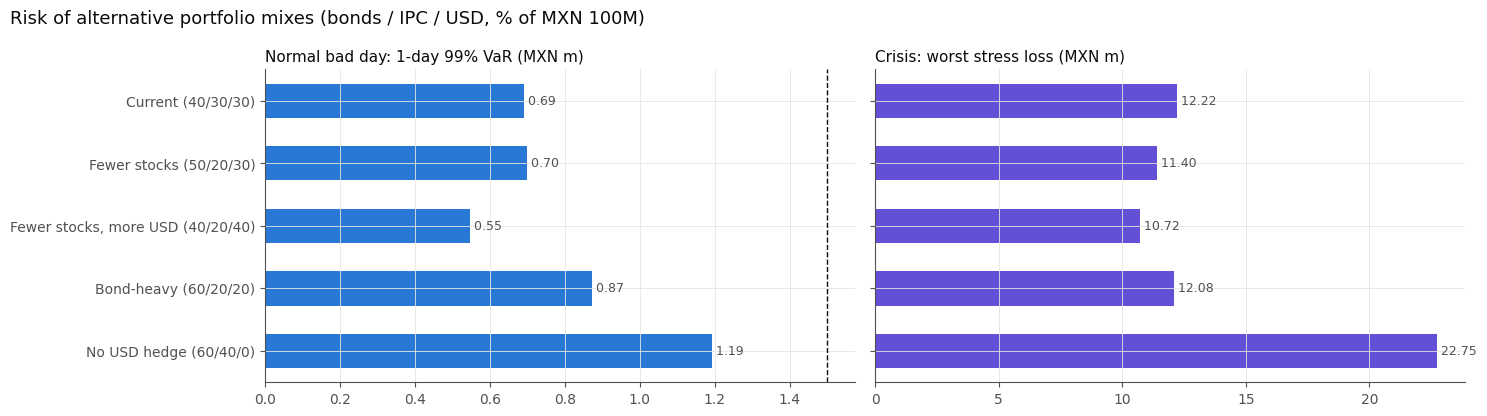

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
yy = np.arange(len(mix_table))
axes[0].barh(yy, mix_table["VaR_99_1d_MXN_m"], color="#2a78d6", height=0.55)
axes[0].axvline(RISK_LIMIT / 1e6, color=INK, linestyle="--", linewidth=1)          # daily risk limit
axes[0].set_title("Normal bad day: 1-day 99% VaR (MXN m)", loc="left", color=INK, fontsize=11)
axes[1].barh(yy, mix_table["Worst_stress_MXN_m"], color="#6250d6", height=0.55)
axes[1].set_title("Crisis: worst stress loss (MXN m)", loc="left", color=INK, fontsize=11)
for ax, col in zip(axes, ["VaR_99_1d_MXN_m", "Worst_stress_MXN_m"]):
    for i, v in enumerate(mix_table[col]):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=9, color=MUTED)
axes[0].set_yticks(yy); axes[0].set_yticklabels(mix_table.index); axes[0].invert_yaxis()
fig.suptitle("Risk of alternative portfolio mixes (bonds / IPC / USD, % of MXN 100M)",
             x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.savefig("/content/images/portfolio_mix.png", dpi=150, bbox_inches="tight")   # saved for the README
plt.show()

**Finding:**

**Moving 10% from stocks into US dollars (40/20/40) lowers risk on every measure, while removing the USD position nearly doubles it**
- **Fewer stocks, more USD (40/20/40)** is the safest mix on every measure: 1-day 99% VaR falls from MXN 0.69M to **MXN 0.55M**, full-history ES from MXN 1.33M to MXN 1.03M, the 2008 worst-10-day loss from MXN 8.44M to **MXN 5.33M**, the 2018 sell-off loss from MXN 6.35M to MXN 3.35M and the Banxico scenario loss from MXN 5.30M to **MXN 1.80M**.
- **Fewer stocks, more bonds (50/20/30)** helps in crises (2008: MXN 6.99M, 2018: MXN 5.10M) but does not lower normal-day VaR (MXN 0.70M), and the Banxico scenario becomes slightly worse (MXN 5.50M) because of the larger bond position.
- **Bond-heavy (60/20/20)** is riskier than today's mix on almost every measure (VaR MXN 0.87M, Banxico scenario MXN 9.20M), so cutting stocks only helps if the money does **not** go into more interest-rate risk.
- **No USD hedge (60/40/0)** is by far the riskiest: VaR rises to MXN 1.19M, ES to MXN 2.51M and the worst stress loss to **MXN 22.75M**, almost twice today's level. This confirms how much protection the USD position provides.
- **The hedge-failure scenario remains the worst case for every mix with a USD position** (MXN 10.72M to MXN 12.22M). Even the safest mix still loses more than 10% of the portfolio if stocks and bonds fall while the peso strengthens, so changing the mix alone does not remove this risk.
- All mixes stay within the MXN 1.5M daily VaR limit.

## 5.2 Key numbers

The most important results from Sections 2–4 in one table, pulled directly from the earlier outputs, as a quick reference for the conclusions below.

In [120]:
key_numbers = pd.DataFrame([
    ("Normal bad day (Section 2)", "1-day 99% VaR, range across 4 methods",
     f"MXN {var_summary['VaR_99_1d'].min():.2f}M – {var_summary['VaR_99_1d'].max():.2f}M"),
    ("Normal bad day (Section 2)", "1-day 99% ES, range across 4 methods",
     f"MXN {var_summary['ES_99_1d'].min():.2f}M – {var_summary['ES_99_1d'].max():.2f}M"),
    ("Normal bad day (Section 2)", "Diversification (99% VaR)",
     f"MXN {contrib.loc['total', 'standalone_VaR_MXN_m']:.2f}M standalone vs "
     f"{contrib.loc['total', 'component_VaR_MXN_m']:.2f}M combined"),
    ("Model reliability (Section 3)", f"99% breaches vs expected ({score['expected_breaches'].iloc[0]:.0f})",
     ", ".join(f"{m}: {int(r)}" for m, r in score["actual_breaches"].sort_values().items())),
    ("Model reliability (Section 3)", "Methods passing both tests at 99%",
     f"{int((score['result'] == 'PASS').sum())} of {len(score)}"),
    ("Crisis (Section 4)", "Worst historical stress loss",
     f"MXN {compare.loc[compare['type'] == 'Historical', 'loss_MXN_m'].max():.2f}M"),
    ("Crisis (Section 4)", "Worst hypothetical stress loss",
     f"MXN {compare.loc[compare['type'] == 'Hypothetical', 'loss_MXN_m'].max():.2f}M"),
    ("Crisis (Section 4)", "Largest stress loss vs 10-day 99% VaR",
     f"{compare.loc[~compare['is_one_day'], 'x_VaR'].max():.2f}x"),
], columns=["question", "measure", "result"]).set_index(["question", "measure"])
key_numbers

result
question                      measure                                                                                 
Normal bad day (Section 2)    1-day 99% VaR, range across 4 methods                                  MXN 0.69M – 0.94M
                              1-day 99% ES, range across 4 methods                                   MXN 0.74M – 1.32M
                              Diversification (99% VaR)                         MXN 1.58M standalone vs 0.82M combined
Model reliability (Section 3) 99% breaches vs expected (46)          Student-t: 52, EWMA (normal): 62, Historical: ...
                              Methods passing both tests at 99%                                                 0 of 4
Crisis (Section 4)            Worst historical stress loss                                                   MXN 8.44M
                              Worst hypothetical stress loss                                                MXN 12.22M
                              Largest stress loss vs 10-day 99% VaR                                              4.11x

**Outcome:** On a normal bad day, the portfolio could lose MXN 0.69M–0.94M (1-day 99% VaR), with an average bad-day loss (ES) of MXN 0.74M–1.32M; holding the three assets together cuts risk from MXN 1.58M to MXN 0.82M. Over 18 years of backtesting, the 99% VaR methods recorded between 52 (Student-t) and 70 (parametric) breaches against 46 expected, and none passed both tests. In a crisis, the worst historical loss is MXN 8.44M and the worst hypothetical loss MXN 12.22M, up to 4.11 times today's 10-day VaR.

## 5.3 Overall summary, business implications and recommendations

**Summary**

**Data (Upload Data):** 20 years of daily market data (Jan 2007 – Nov 2026) were collected from the Banxico API, Yahoo Finance and Investing.com, stored in SQLite and validated with six checks. The result is 4,850 clean daily changes covering the 2008, 2016, 2018 and 2020 crises.

**Section 1 – Risk factors and P&L**
- All three markets have **fat tails**: extreme days happen 5–6 times more often than a normal distribution predicts.
- Markets move together more strongly in crises (e.g., stocks vs bond yields: −0.17 calm vs −0.44 crisis), so diversification weakens when it is most needed.
- The USD position acts as a natural hedge, gaining on 7 of the 10 worst days, and holding the three assets together **halves** daily risk (−50%).

**Section 2 – VaR and Expected Shortfall**
- On a normal bad day (1-day 99%), the portfolio could lose **MXN 0.69M–0.94M**, well within the MXN 1.5M limit.
- The past year was calmer than usual (99% VaR MXN 0.69M vs MXN 0.96M over the full history), and the fat-tailed Student-t model gives the most realistic estimate (VaR MXN 0.94M, ES MXN 1.32M).
- The **IPC stock position drives 69% of the risk** with only 30% of the capital.

**Section 3 – Backtesting**
- All methods are reliable at 95%, but **none fully passes at 99%** over 4,600 days.
- The normal-distribution model is the weakest (70 breaches vs 46 expected, one Basel red-zone year). Student-t gets the breach count right (52) but reacts slowly; EWMA reacts fastest (no back-to-back breaches, 15 of 19 green years).
- Models based on a fixed 250-day window warn late in a crisis and stay too high afterwards (above the limit on 205–213 days in 2009).

**Section 4 – Stress testing**
- A repeat of **2008** would cost today's portfolio **MXN 8.44M in two weeks** (2.8× 10-day VaR), and the **2018 Mexico sell-off** MXN 6.35M.
- The worst case is a **hedge failure** (stocks and bonds fall while the peso strengthens): **MXN 12.22M, 12.2% of the portfolio** (4.1× 10-day VaR).
- The USD position protects well in global crises (2008, 2020) but much less in a domestic crisis (2018).

**Section 5 – Portfolio mix**
- Moving 10% from stocks into US dollars (**40/20/40**) lowers risk on every measure: VaR −20% (MXN 0.69M → 0.55M), 2008 loss −37% (MXN 8.44M → 5.33M), Banxico scenario −66% (MXN 5.30M → 1.80M).
- Removing the USD position would almost **double** the worst stress loss (MXN 22.75M).
- No mix removes the hedge-failure risk: the safest mix still loses MXN 10.72M in that scenario.

---

**Business implications**
1. **The portfolio is safe on normal days but exposed in a crisis.** Daily risk is well within the limit, but crisis losses are up to four times larger than VaR. Managing it with VaR alone would give a false sense of security.
2. **The wrong model would understate risk.** The normal-distribution VaR was breached 52% more often than expected and would have triggered a regulatory capital penalty. A fat-tailed, fast-reacting model is needed for limits and capital.
3. **Stocks are the main risk, and the peso is the main protection.** The IPC position drives most losses, while the USD position cuts them sharply in global crises. Removing it would almost double crisis losses.
4. **The portfolio's biggest blind spot is a local Mexican crisis or a peso rally.** In these cases stocks and bonds fall with little or no offset from the USD position, and losses can exceed 10% of the portfolio.
5. **Timing matters.** Losses can build up over weeks (2018), and slow models warn too late, so an early-warning signal is as important as an accurate VaR.

---

**Recommendations**
1. **Rebalance from 40/30/30 to 40/20/40** (move 10% from stocks to US dollars).
   *Insight:* this mix lowers VaR, ES and every crisis loss tested (e.g., 2008: MXN 8.44M → 5.33M).
   *Note:* this analysis measures risk only. The expected return lost by holding fewer stocks should be reviewed before rebalancing, and a 40% USD position increases exposure to a peso rally.
2. **Replace the normal-distribution VaR with a fat-tailed, fast-reacting model.**
   *Insight:* Student-t gets the number of breaches right and EWMA reacts fastest. → Combine them (EWMA volatility + Student-t distribution) for limits and capital; until then, use EWMA as the daily VaR and Student-t as a conservative check.
3. **Add a stress loss limit next to the daily VaR limit.**
   *Insight:* crisis losses reach MXN 12.22M while daily VaR is below MXN 1M. → Set a limit such as "worst stress scenario ≤ 10% of the portfolio" and review it monthly.
4. **Protect against the hedge-failure and domestic-crisis scenarios.**
   *Insight:* every mix with a USD position still loses more than 10% if the peso strengthens while stocks and bonds fall. → Run these scenarios monthly and consider direct hedges for stocks and bonds (e.g., IPC futures, interest-rate swaps) instead of relying only on the peso.
5. **Use EWMA VaR as an early-warning signal.**
   *Insight:* EWMA was the only model to flag the 2018 and 2020 stress periods. → Cut positions when EWMA VaR rises above the MXN 1.5M limit, before losses build up.

**Limitations**
- The bond is modelled as a generic 10-year par bond, using a single free data source for yields.
- Positions are held at fixed weights; stress losses assume no trading during a crisis.
- Hypothetical scenarios and the MXN 1.5M limit are assumptions for illustration.
- Portfolio mixes are compared on risk only, not on expected return.

Download chart images for the README

In [ ]:
# Zip all saved charts and download them, to upload to the images/ folder in the GitHub repo
import shutil
from google.colab import files
shutil.make_archive("/content/images", "zip", "/content/images")
files.download("/content/images.zip")